# Org shot classification

In [4]:
import math
import json
from typing import Tuple, List, Dict, Any, Optional

import numpy as np
import pandas as pd

# ============================================================================
# Helper Functions
# ============================================================================

def parse_xy(val) -> Optional[Tuple[float, float]]:
    """Parse [x,y] stored as list/tuple or JSON-like string; None if not parseable."""
    if isinstance(val, (list, tuple)) and len(val) >= 2:
        try:
            return float(val[0]), float(val[1])
        except Exception:
            return None
    if isinstance(val, str):
        s = val.strip()
        if not s:
            return None
        try:
            j = json.loads(s.replace("'", '"'))
            if isinstance(j, (list, tuple)) and len(j) >= 2:
                return float(j[0]), float(j[1])
        except Exception:
            return None
    return None

def dist_to_nearest_goal(xy: Tuple[float, float]) -> float:
    """Euclidean distance from (x,y) to the nearest goal center in SB units (≈ yards)."""
    x, y = xy
    d_left  = math.hypot(x - 0.0,   y - 40.0)
    d_right = math.hypot(x - 120.0, y - 40.0)
    return min(d_left, d_right)

def get_pass_row_by_id(events: pd.DataFrame, pass_id: Any) -> Optional[pd.Series]:
    """Find the pass row by its `id` (string match after strip)."""
    if "id" not in events.columns:
        return None
    m = events[events["id"].astype(str).str.strip() == str(pass_id).strip()]
    return None if m.empty else m.iloc[0]

# ============================================================================
# Extract Important Moments
# ============================================================================

def important_moments_from_file(
    filename: str,
    xg_threshold: float = 0.08,
) -> Tuple[pd.DataFrame, List[Dict[str, Any]]]:
    """
    Returns (moments_df, moments_list) for a match events CSV.
    Each moment includes the original event `id`.

    Moments:
      - Shots with xG >= xg_threshold OR shot_outcome == "Goal"
      - Own Goal Against
      - Foul Won with foul_won_penalty == True  (labeled as 'Penalty Won')

    Post-processing:
      - Filter out events after 120:00 if minute/second exist
      - Sort by period, minute, second, timestamp (when present)
      - If `possession` exists, keep the last event per possession (dedupe)
      - Make values JSON-safe (NaN/inf -> None; numpy scalars -> native)
    """
    df = pd.read_csv(filename)

    # --- Prepare shots & xG ---
    shots = df[df["type"] == "Shot"].copy() if "type" in df.columns else pd.DataFrame()
    if not shots.empty:
        if "shot_statsbomb_xg" in shots.columns:
            shots["xg"] = pd.to_numeric(shots["shot_statsbomb_xg"], errors="coerce")
        else:
            shots["xg"] = np.nan
        shot_mask = (shots["xg"] >= xg_threshold) | (shots.get("shot_outcome", "") == "Goal")
        shots = shots[shot_mask]
    # --- Own goals ---
    own_goals = df[df["type"] == "Own Goal Against"].copy() if "type" in df.columns else pd.DataFrame()
    if not own_goals.empty:
        own_goals["xg"] = np.nan  # no xG for own goals

    # --- Penalty won (foul won with penalty flag) ---
    pen_won = pd.DataFrame()
    if "type" in df.columns and "foul_won_penalty" in df.columns:
        pen_won = df[(df["type"] == "Foul Won") & (df["foul_won_penalty"] == True)].copy()
        if not pen_won.empty:
            pen_won["xg"] = np.nan  # not a shot, but keep xg column for schema consistency

    # --- Combine candidates ---
    moments = pd.concat([shots, own_goals, pen_won], ignore_index=True)

    # Nothing matched
    if moments.empty:
        return moments, []

    # --- Time filter: remove events strictly after 120:00 ---
    if {"minute", "second"}.issubset(moments.columns):
        mask = (moments["minute"] < 120) | ((moments["minute"] == 120) & (moments["second"].fillna(0) <= 0))
        moments = moments[mask].copy()

    # --- Sort by match order ---
    sort_cols = [c for c in ["period", "minute", "second", "timestamp"] if c in moments.columns]
    if sort_cols:
        moments = moments.sort_values(sort_cols, ascending=True, kind="stable")

    # --- Group by possession: keep last in each possession (if possession exists) ---
    if "possession" in moments.columns:
        # Secondary sort to ensure "last()" is deterministic with timestamp when available
        sort_cols2 = [c for c in ["possession", "period", "minute", "second", "timestamp"] if c in moments.columns]
        moments = moments.sort_values(sort_cols2, ascending=True, kind="stable")
        moments = moments.groupby("possession", as_index=False).last()

    # --- Drop exact duplicates if any ---
    moments = moments.drop_duplicates()

    # --- Create a tidy projection with stable columns ---
    def safe(val):
        if val is None:
            return None
        if isinstance(val, float) and (math.isnan(val) or math.isinf(val)):
            return None
        return val

    # Build a clean DataFrame with key fields; keep event `id`
    keep_cols = []
    for c in ["id","match_id","type","team","player","minute","second","timestamp","period","possession","xg","shot_outcome"]:
        if c in moments.columns:
            keep_cols.append(c)

    moments_df = moments[keep_cols].copy()

    # Label "Penalty Won" outcome for the Foul Won + flag case (nice-to-have)
    if {"type", "shot_outcome", "foul_won_penalty"}.issubset(moments.columns):
        mask_pw = (moments["type"] == "Foul Won") & (moments["foul_won_penalty"] == True)
        moments_df.loc[mask_pw.values, "shot_outcome"] = "Penalty Won"

    # JSON-safe list of dicts
    def json_fallback(o):
        if isinstance(o, (np.integer,)):
            return int(o)
        if isinstance(o, (np.floating,)):
            return None if np.isnan(o) else float(o)
        if isinstance(o, (np.bool_,)):
            return bool(o)
        return str(o)

    # Replace NaNs with None for JSON
    moments_df = moments_df.replace([np.nan, np.inf, -np.inf], None)

    moments_list: List[Dict[str, Any]] = []
    for _, row in moments_df.iterrows():
        # Compact "who" label like "C. Immobile"
        who = "N/A"
        player = row.get("player", None)
        if isinstance(player, str) and player.strip():
            parts = player.split()
            who = f"{parts[0][0]}. {parts[-1]}" if len(parts) >= 2 else parts[0]

        # "when" as mm:ss if minute/second present
        m, s = row.get("minute", None), row.get("second", None)
        when = f"{int(m)}:{int(s):02d}" if (m is not None and s is not None) else row.get("timestamp", None) or "N/A"

        item = {
            "event_id": row.get("id"),                           # <-- include original event id
            "match_id": row.get("match_id", None),
            "possession": row.get("possession", None),
            "who": who,
            "when": when,
            "event_type": row.get("type", None),
            "xg": row.get("xg", None),
            "outcome": row.get("shot_outcome", None),
            "team": row.get("team", None),
        }
        # JSON-safe coercion
        for k, v in list(item.items()):
            try:
                item[k] = v if v is None else json.loads(json.dumps(v, default=json_fallback))
            except Exception:
                item[k] = None if v is None else str(v)
        moments_list.append(item)

    return moments_df, moments_list

# ============================================================================
# Classify Shot Moments
# ============================================================================

def classify_shot_moments(
    filename: str,
    moments_df: pd.DataFrame,
    long_shot_yards: float = 22.0
) -> pd.DataFrame:
    """
    Classify important moments where type == 'Shot' with multi-labels and xG.

    Labels:
      - From key pass flags (on the pass row referenced by `shot_key_pass_id`):
          pass_through_ball, pass_cross, pass_cut_back
      - 'Long Shot' if distance to nearest goal center >= long_shot_yards
      - 'other' if none matched

    Returns a DataFrame with one row per shot moment.
    """
    # Load full events for lookups (shot_key_pass_id, locations, xg, etc.)
    ev = pd.read_csv(filename)

    # Tolerant type column
    type_col = "type" if "type" in ev.columns else ("Type" if "Type" in ev.columns else None)
    if type_col is None:
        raise ValueError("No 'type'/'Type' column in events CSV.")

    # Shots in the full events (we'll use this to get fields not present in moments_df)
    ev_shots = ev[ev[type_col].astype(str).str.lower() == "shot"].copy()

    # Ensure an xg column exists on ev_shots
    if "shot_statsbomb_xg" in ev_shots.columns:
        ev_shots["xg"] = pd.to_numeric(ev_shots["shot_statsbomb_xg"], errors="coerce")
    else:
        ev_shots["xg"] = np.nan

    # Focus only on the events that are marked as important moments AND are shots
    if "type" not in moments_df.columns:
        raise ValueError("moments_df must include a 'type' column.")
    shot_ids = set(moments_df.loc[moments_df["type"] == "Shot", "id"]) if "id" in moments_df.columns else set()

    # If moments_df didn't carry 'id', fall back to intersect by time/team (not ideal). We require 'id'.
    if not shot_ids:
        raise ValueError("moments_df must include 'id' for shot events to classify them.")

    shots_focus = ev_shots[ev_shots["id"].isin(shot_ids)].copy()

    # Prepare output rows
    out_rows: List[Dict[str, Any]] = []

    for _, r in shots_focus.iterrows():
        labels: List[str] = []

        # 1) pass-based labels via key pass flags
        kp = r.get("shot_key_pass_id", np.nan)
        if pd.notna(kp):
            prow = get_pass_row_by_id(ev, kp)
            if prow is not None:
                # Only the three you asked for
                if "pass_through_ball" in prow.index and pd.notna(prow["pass_through_ball"]) and bool(prow["pass_through_ball"]):
                    labels.append("pass_through_ball")
                if "pass_cross" in prow.index and pd.notna(prow["pass_cross"]) and bool(prow["pass_cross"]):
                    labels.append("pass_cross")
                if "pass_cut_back" in prow.index and pd.notna(prow["pass_cut_back"]) and bool(prow["pass_cut_back"]):
                    labels.append("pass_cut_back")

        # 2) long shot (>= threshold yards to nearest goal center)
        loc = parse_xy(r.get("location"))
        dist_goal = float("nan")
        if loc is not None:
            dist_goal = dist_to_nearest_goal(loc)
            if dist_goal >= float(long_shot_yards):
                labels.append("Long Shot")

        # 3) other if nothing else matched
        if len(labels) == 0:
            labels.append("other")

        out_rows.append({
            "id": r.get("id"),
            "match_id": r.get("match_id"),
            "team": r.get("team"),
            "player": r.get("player"),
            "minute": r.get("minute"),
            "second": r.get("second"),
            "shot_outcome": r.get("shot_outcome"),
            "xg": r.get("xg"),
            "distance_to_goal": dist_goal,
            "labels": labels,
            "labels_str": ";".join(labels),
            "shot_key_pass_id": r.get("shot_key_pass_id"),
        })

    shot_moments_labeled = pd.DataFrame(out_rows)

    # Keep only the original important shot ids order if you want
    order_ids = moments_df.loc[moments_df["type"] == "Shot", "id"].tolist()
    if "id" in shot_moments_labeled.columns:
        shot_moments_labeled["__order"] = shot_moments_labeled["id"].apply(lambda x: order_ids.index(x) if x in order_ids else 10**9)
        shot_moments_labeled = shot_moments_labeled.sort_values("__order").drop(columns="__order")

    return shot_moments_labeled

# ============================================================================
# Usage Example
# ============================================================================

if __name__ == "__main__":
    # Set your file path
    FILENAME = "events_by_match/events_3788741.csv"
    # Step 1: Extract important moments
    print("Extracting important moments...")
    moments_df, moments_list = important_moments_from_file(FILENAME, xg_threshold=0.08)
    
    print(f"\nFound {len(moments_df)} important moments")
    print("\nMoments DataFrame:")
    with pd.option_context("display.max_columns", 50, "display.width", 180):
        print(moments_df.to_string(index=False))
    
    # Step 2: Classify shots from important moments
    print("\n\nClassifying shots...")
    shot_moments_labeled = classify_shot_moments(FILENAME, moments_df, long_shot_yards=22.0)
    
    print(f"\nClassified {len(shot_moments_labeled)} shots")
    print("\nLabeled Shots DataFrame:")
    with pd.option_context("display.max_columns", 50, "display.width", 180):
        print(shot_moments_labeled.to_string(index=False))
    
    # Optional: Save results
    # moments_df.to_csv("important_moments.csv", index=False)
    # shot_moments_labeled.to_csv("shot_moments_labeled.csv", index=False)
    # with open("important_moments.json", "w", encoding="utf-8") as f:
    #     json.dump(moments_list, f, ensure_ascii=False, indent=2)

Extracting important moments...

Found 7 important moments

Moments DataFrame:
                                  id  match_id             type   team           player  minute  second    timestamp  period  possession        xg shot_outcome
74750b41-c816-4a6c-88d3-b98859039c74   3788741             Shot  Italy  Lorenzo Insigne      17       3 00:17:03.251       1          38  0.098552        Off T
c07133d1-fa88-45f8-8a40-7be381ddffd1   3788741             Shot  Italy Domenico Berardi      44      33 00:44:33.641       1         108  0.128881        Off T
4a9f326b-e5c1-4d81-bc98-d0992cf85a00   3788741 Own Goal Against Turkey    Merih Demiral      52      12 00:07:12.643       2         125      None         None
c12c958c-b795-4471-b81c-c16582d8205a   3788741             Shot  Italy  Lorenzo Insigne      56      21 00:11:21.502       2         133  0.086273      Blocked
506e2e45-cc7a-4aa8-9c0d-2c8fb339bc2f   3788741             Shot  Italy    Ciro Immobile      65      33 00:20:33.192     

# Case 1: pass_cross/through ball

In [1]:
# %% Imports
import math
import json
from typing import Tuple, List, Dict, Any, Optional

import numpy as np
import pandas as pd

In [2]:
# %% Core Helper Functions from Z
def parse_xy(val) -> Optional[Tuple[float, float]]:
    """Parse [x,y] stored as list/tuple or JSON-like string; None if not parseable."""
    if isinstance(val, (list, tuple)) and len(val) >= 2:
        try:
            return float(val[0]), float(val[1])
        except Exception:
            return None
    if isinstance(val, str):
        s = val.strip()
        if not s:
            return None
        try:
            j = json.loads(s.replace("'", '"'))
            if isinstance(j, (list, tuple)) and len(j) >= 2:
                return float(j[0]), float(j[1])
        except Exception:
            return None
    return None

def dist_to_nearest_goal(xy: Tuple[float, float]) -> float:
    """Euclidean distance from (x,y) to the nearest goal center in SB units (≈ yards).
    
    Goals are fixed at:
    - Left goal: (0, 40)
    - Right goal: (120, 40)
    """
    x, y = xy
    d_left  = math.hypot(x - 0.0,   y - 40.0)
    d_right = math.hypot(x - 120.0, y - 40.0)
    return min(d_left, d_right)

def get_pass_row_by_id(events: pd.DataFrame, pass_id: Any) -> Optional[pd.Series]:
    """Find the pass row by its `id` (string match after strip)."""
    if "id" not in events.columns:
        return None
    m = events[events["id"].astype(str).str.strip() == str(pass_id).strip()]
    return None if m.empty else m.iloc[0]


# %% Calculate distance pass travels toward goal
def pass_distance_toward_goal(pass_location: Tuple[float, float], 
                                pass_end_location: Tuple[float, float]) -> float:
    """
    Calculate how far a pass travels toward the goal.
    
    The goal is fixed at (120, 40) - the right side of the pitch.
    We calculate distance to this goal from both locations and see if the pass
    moves closer to the goal.
    
    Args:
        pass_location: Starting location (x, y)
        pass_end_location: Ending location (x, y)
    
    Returns:
        Distance traveled toward goal (positive if moving toward, 0 if not)
    """
    x1, y1 = pass_location
    x2, y2 = pass_end_location
    
    # Distance to goal (120, 40) from start location
    dist_start_to_goal = math.hypot(x1 - 120.0, y1 - 40.0)
    
    # Distance to goal (120, 40) from end location
    dist_end_to_goal = math.hypot(x2 - 120.0, y2 - 40.0)
    
    # Distance traveled toward goal (positive if end is closer than start)
    distance_toward_goal = dist_start_to_goal - dist_end_to_goal
    
    # Return positive value only if moving toward goal, otherwise 0
    return max(0.0, distance_toward_goal)


# %% Check Case 1: pass_cross = 0 AND pass travels > 5m toward goal
def check_case1_pass_toward_goal(events_df: pd.DataFrame, 
                                  pass_id: Any, 
                                  threshold_meters: float = 5.0) -> bool:
    """
    Check if a pass (referenced by pass_id) satisfies Case 1:
    - pass_cross column = 0 (False/0/NaN)
    - Pass travels > threshold_meters toward goal
    
    Args:
        events_df: Full events DataFrame
        pass_id: ID of the pass event to check
        threshold_meters: Distance threshold (default 5.0 meters)
    
    Returns:
        True if both conditions are met, False otherwise
    """
    # Find the pass row
    pass_row = get_pass_row_by_id(events_df, pass_id)
    if pass_row is None:
        return False
    
    # Check pass_cross = 0 (False, 0, or NaN)
    pass_cross_val = pass_row.get("pass_cross", np.nan)
    is_not_cross = (
        pd.isna(pass_cross_val) or 
        pass_cross_val == False or 
        pass_cross_val == 0 or
        (isinstance(pass_cross_val, str) and pass_cross_val.lower() in ['false', '0', ''])
    )
    
    if not is_not_cross:
        return False  # pass_cross is not 0, so Case 1 fails
    
    # Get pass locations
    pass_loc = parse_xy(pass_row.get("location"))
    pass_end_loc = parse_xy(pass_row.get("pass_end_location"))
    
    if pass_loc is None or pass_end_loc is None:
        return False  # Missing location data
    
    # Calculate distance traveled toward goal
    dist_toward_goal = pass_distance_toward_goal(pass_loc, pass_end_loc)
    
    # Check if distance > threshold
    return dist_toward_goal > threshold_meters


# %% Classify shot moments with Case 1 (exclusive label)
def classify_shot_moments(
    filename: str,
    moments_df: pd.DataFrame,
    long_shot_yards: float = 22.0,
    case1_threshold_meters: float = 5.0
) -> pd.DataFrame:
    """
    Classify important moments where type == 'Shot' with multi-labels and xG.
    
    IMPORTANT: Case 1 is EXCLUSIVE - if it applies, label is ONLY "case1_pass_through_ball"
    
    Labels:
      - Case 1 (exclusive): 'case1_pass_through_ball' if pass_cross=0 AND pass travels > threshold toward goal
      - If Case 1 doesn't apply, then check:
          - pass_through_ball, pass_cross, pass_cut_back (from key pass flags)
          - 'Long Shot' if distance to nearest goal center >= long_shot_yards
          - 'other' if none matched

    Returns a DataFrame with one row per shot moment.
    """
    # Load full events for lookups (shot_key_pass_id, locations, xg, etc.)
    ev = pd.read_csv(filename)

    # Tolerant type column
    type_col = "type" if "type" in ev.columns else ("Type" if "Type" in ev.columns else None)
    if type_col is None:
        raise ValueError("No 'type'/'Type' column in events CSV.")

    # Shots in the full events
    ev_shots = ev[ev[type_col].astype(str).str.lower() == "shot"].copy()

    # Ensure an xg column exists on ev_shots
    if "shot_statsbomb_xg" in ev_shots.columns:
        ev_shots["xg"] = pd.to_numeric(ev_shots["shot_statsbomb_xg"], errors="coerce")
    else:
        ev_shots["xg"] = np.nan

    # Focus only on the events that are marked as important moments AND are shots
    if "type" not in moments_df.columns:
        raise ValueError("moments_df must include a 'type' column.")
    shot_ids = set(moments_df.loc[moments_df["type"] == "Shot", "id"]) if "id" in moments_df.columns else set()

    if not shot_ids:
        raise ValueError("moments_df must include 'id' for shot events to classify them.")

    shots_focus = ev_shots[ev_shots["id"].isin(shot_ids)].copy()

    # Prepare output rows
    out_rows: List[Dict[str, Any]] = []

    for _, r in shots_focus.iterrows():
        labels: List[str] = []
        case1_applies = False

        # Check if shot has a key pass
        kp = r.get("shot_key_pass_id", np.nan)
        if pd.notna(kp):
            # FIRST: Check Case 1 (exclusive)
            if check_case1_pass_toward_goal(ev, kp, threshold_meters=case1_threshold_meters):
                labels.append("case1_pass_through_ball")
                case1_applies = True
            else:
                # Only check other labels if Case 1 doesn't apply
                prow = get_pass_row_by_id(ev, kp)
                if prow is not None:
                    # Original pass flags
                    if "pass_through_ball" in prow.index and pd.notna(prow["pass_through_ball"]) and bool(prow["pass_through_ball"]):
                        labels.append("pass_through_ball")
                    if "pass_cross" in prow.index and pd.notna(prow["pass_cross"]) and bool(prow["pass_cross"]):
                        labels.append("pass_cross")
                    if "pass_cut_back" in prow.index and pd.notna(prow["pass_cut_back"]) and bool(prow["pass_cut_back"]):
                        labels.append("pass_cut_back")

        # Long shot check (only if Case 1 doesn't apply)
        if not case1_applies:
            loc = parse_xy(r.get("location"))
            dist_goal = float("nan")
            if loc is not None:
                dist_goal = dist_to_nearest_goal(loc)
                if dist_goal >= float(long_shot_yards):
                    labels.append("Long Shot")

        # Other label (only if Case 1 doesn't apply and no other labels)
        if not case1_applies and len(labels) == 0:
            labels.append("other")

        # Calculate distance to goal for all shots (for reference)
        loc = parse_xy(r.get("location"))
        dist_goal = float("nan")
        if loc is not None:
            dist_goal = dist_to_nearest_goal(loc)

        out_rows.append({
            "id": r.get("id"),
            "match_id": r.get("match_id"),
            "team": r.get("team"),
            "player": r.get("player"),
            "minute": r.get("minute"),
            "second": r.get("second"),
            "shot_outcome": r.get("shot_outcome"),
            "xg": r.get("xg"),
            "distance_to_goal": dist_goal,
            "labels": labels,
            "labels_str": ";".join(labels),
            "shot_key_pass_id": r.get("shot_key_pass_id"),
        })

    shot_moments_labeled = pd.DataFrame(out_rows)

    # Keep only the original important shot ids order if you want
    order_ids = moments_df.loc[moments_df["type"] == "Shot", "id"].tolist()
    if "id" in shot_moments_labeled.columns:
        shot_moments_labeled["__order"] = shot_moments_labeled["id"].apply(lambda x: order_ids.index(x) if x in order_ids else 10**9)
        shot_moments_labeled = shot_moments_labeled.sort_values("__order").drop(columns="__order")

    return shot_moments_labeled


# %% Core Helper Functions from F


def add_soccer_ball(ax, x, y, size=0.05):
    ball_img = mpimg.imread("soccer_ball.png")  # path to your ball icon
    imagebox = OffsetImage(ball_img, zoom=size)
    ab = AnnotationBbox(imagebox, (x, y), frameon=False)
    ax.add_artist(ab)

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import math

def plot_three_sixty(
    df, 
    ball_icon_path="soccer_ball.png", 
    ball_zoom=0.0055,
    pass_x_start=None,
    pass_y_start=None,
    pass_x_end=None,
    pass_y_end=None
):
    """
    Plots player locations from a three-sixty dataframe with columns:
    id, match_id, visible_area, teammate, actor, keeper, location.
    Teammates: blue, Keepers: red, Others: gray.
    If 'actor' == 1, mark with ring and draw a soccer ball next to their dot.
    Optionally, draw a thin black arrow for the pass from (pass_x_start, pass_y_start) to (pass_x_end, pass_y_end)
    For each defender (teammate==0, keeper==0) with a defender_8m_circle, also plot the 8m circle in light yellow.

    In addition, for every pair of defenders whose circles overlap, draws a grey dotted line between their centers.

    Parameters
    ----------
    df : pandas.DataFrame
        Three-sixty dataframe with 'location', 'teammate', 'keeper', and 'actor' columns.
    ball_icon_path : str
        Path to soccer ball PNG.
    ball_zoom : float
        Scaling factor for soccer ball size (default 0.05).
    pass_x_start, pass_y_start, pass_x_end, pass_y_end : float, optional
        Coordinates to draw the pass arrow. If any are None, no arrow is drawn.
    """

    # --- Helper: Draw pitch ---
    def draw_pitch(ax, pitch_length=120, pitch_width=80):
        ax.plot([0, 0], [0, pitch_width], color="black")
        ax.plot([0, pitch_length], [pitch_width, pitch_width], color="black")
        ax.plot([pitch_length, pitch_length], [pitch_width, 0], color="black")
        ax.plot([pitch_length, 0], [0, 0], color="black")
        ax.plot([pitch_length/2, pitch_length/2], [0, pitch_width], color="black")

        ax.plot([102, 102], [18, pitch_width-18], color="black")  # Right PA
        ax.plot([pitch_length, 102], [18, 18], color="black")
        ax.plot([pitch_length, 102], [pitch_width-18, pitch_width-18], color="black")
        ax.plot([18, 18], [18, pitch_width-18], color="black")
        ax.plot([0, 18], [18, 18], color="black")
        ax.plot([0, 18], [pitch_width-18, pitch_width-18], color="black")

        centreCircle = plt.Circle((pitch_length/2, pitch_width/2), 10, color="black", fill=False)
        ax.add_patch(centreCircle)

        from matplotlib.patches import Rectangle, Circle
        ax.add_patch(Rectangle((-0.5, 36), 0.5, 8, fill=False, ec="black", lw=2))
        ax.add_patch(Rectangle((pitch_length, 36), 0.5, 8, fill=False, ec="black", lw=2))
        ax.add_patch(Rectangle((0, (pitch_width/2)-10), 6, 20, fill=False, ec="black", lw=1))
        ax.add_patch(Rectangle((pitch_length-6, (pitch_width/2)-10), 6, 20, fill=False, ec="black", lw=1))
        ax.add_patch(Circle((12, pitch_width/2), 0.7, color='black'))
        ax.add_patch(Circle((pitch_length-12, pitch_width/2), 0.7, color='black'))

        ax.set_xlim(0, pitch_length)
        ax.set_ylim(0, pitch_width)
        ax.axis('off')

    # --- Helper: Parse location ---
    def parse_location(loc):
        if isinstance(loc, (list, tuple)) and len(loc) >= 2:
            return float(loc[0]), float(loc[1])
        if isinstance(loc, str):
            try:
                import ast
                pt = ast.literal_eval(loc)
                if isinstance(pt, (list, tuple)) and len(pt) >= 2:
                    return float(pt[0]), float(pt[1])
            except Exception:
                pass
        return None

    # --- Helper: Add soccer ball icon ---
    def add_soccer_ball(ax, x, y, icon_path=ball_icon_path, zoom=ball_zoom):
        try:
            img = mpimg.imread(icon_path)
            imagebox = OffsetImage(img, zoom=zoom)
            ab = AnnotationBbox(imagebox, (x, y), frameon=False, zorder=8)
            ax.add_artist(ab)
        except FileNotFoundError:
            print(f"⚠️ Soccer ball image not found at '{icon_path}'. Skipping icon.")

    # --- Collect player coordinates ---
    x, y, colors = [], [], []
    actors_x, actors_y, actors_color = [], [], []

    # --- Collect defender 8m circles ---
    defender_circles = []
    for _, r in df.iterrows():
        # Add defender 8m circle info if relevant
        if r.get("teammate", 0) == 0 and r.get("keeper", 0) == 0 and ("defender_8m_circle" in r):
            circ = r["defender_8m_circle"]
            if isinstance(circ, dict) and "center" in circ and "radius" in circ:
                center_pt = circ["center"]
                radius = circ["radius"]
                if center_pt is not None:
                    defender_circles.append((center_pt[0], center_pt[1], radius))

        pt = parse_location(r["location"])
        if pt is None:
            continue
        if r.get("teammate", 0) == 1:
            c = "blue"
        elif r.get("keeper", 0) == 1:
            c = "red"
        else:
            c = "gray"

        if r.get("actor", 0) == 1:
            actors_x.append(pt[0])
            actors_y.append(pt[1])
            actors_color.append(c)
        else:
            x.append(pt[0])
            y.append(pt[1])
            colors.append(c)

    # --- Plot setup ---
    fig, ax = plt.subplots(figsize=(10, 7))
    draw_pitch(ax)

    # --- Draw lines between overlapping defender circles ---
    # For each pair of defender circles, check for overlap and draw if they do
    for i in range(len(defender_circles)):
        cx1, cy1, r1 = defender_circles[i]
        for j in range(i+1, len(defender_circles)):
            cx2, cy2, r2 = defender_circles[j]
            dist = math.hypot(cx1 - cx2, cy1 - cy2)
            # Consider a very small epsilon in case of float precision
            if dist <= (r1 + r2) - 1e-6:
                ax.plot(
                    [cx1, cx2], [cy1, cy2], 
                    linestyle=':', color='grey', linewidth=2, zorder=2
                )

    # Draw all 8m defender circles in light yellow under everything else
    for cx, cy, radius in defender_circles:
        circle_patch = plt.Circle(
            (cx, cy), 
            radius, 
            color="#fffcc4",  # light yellow
            fill=True, 
            linewidth=1, 
            zorder=1,
            alpha=0.7,
            edgecolor="gold"
        )
        ax.add_patch(circle_patch)

    # Plot all players
    ax.scatter(x, y, c=colors, s=100, edgecolors='black', zorder=3)

    # Plot actors + soccer ball
    for px, py, c in zip(actors_x, actors_y, actors_color):
        ax.scatter([px], [py], c=c, s=100, edgecolors='black', zorder=5)
        ring = plt.Circle((px, py), 7, color="gold", fill=False, linewidth=2.5, zorder=6)
        ax.add_patch(ring)
        add_soccer_ball(ax, px+3, py)  # small offset to the right

    # --- Draw pass arrow if all values are provided ---
    if (
        pass_x_start is not None and
        pass_y_start is not None and
        pass_x_end is not None and
        pass_y_end is not None
    ):
        ax.annotate(
            '', 
            xy=(pass_x_end, pass_y_end), 
            xytext=(pass_x_start, pass_y_start),
            arrowprops=dict(
                arrowstyle='->', 
                lw=1, 
                color='black',
                shrinkA=0, shrinkB=0,
                mutation_scale=13
            ),
            zorder=10
        )

    plt.show()



def get_overlapping_defender_pairs(df, min_overlap_epsilon=1e-6):
    """
    For a three-sixty dataframe, find all pairs of defenders (teammate==0, keeper==0)
    whose 8m "defender_8m_circle" areas overlap. 
    Returns a list of tuples: (i, j, circle1, circle2)
    where i, j are the row indices and circle1/2 = (cx, cy, radius)
    """
    import math

    # Helper to parse a circle from a row
    def parse_circle(row):
        circ = row.get("defender_8m_circle", None)
        if isinstance(circ, dict) and "center" in circ and "radius" in circ:
            center_pt = circ["center"]
            radius = circ["radius"]
            if center_pt is not None:
                return (float(center_pt[0]), float(center_pt[1]), float(radius))
        return None

    # Collect defender indices and circles
    defenders = []
    for i, r in df.iterrows():
        if r.get("teammate", 0) == 0 and r.get("keeper", 0) == 0:
            c = parse_circle(r)
            if c is not None:
                defenders.append((i, c))

    # Find all pairs with overlapping circles
    pairs = []
    for idx1 in range(len(defenders)):
        i1, c1 = defenders[idx1]
        cx1, cy1, r1 = c1
        for idx2 in range(idx1+1, len(defenders)):
            i2, c2 = defenders[idx2]
            cx2, cy2, r2 = c2
            dist = math.hypot(cx1 - cx2, cy1 - cy2)
            if dist <= (r1 + r2) - min_overlap_epsilon:
                pairs.append((i1, i2, c1, c2))

    return pairs


# --- Helper: Draw pitch ---
def draw_pitch(ax, pitch_length=120, pitch_width=80):
    ax.plot([0, 0], [0, pitch_width], color="black")
    ax.plot([0, pitch_length], [pitch_width, pitch_width], color="black")
    ax.plot([pitch_length, pitch_length], [pitch_width, 0], color="black")
    ax.plot([pitch_length, 0], [0, 0], color="black")
    ax.plot([pitch_length/2, pitch_length/2], [0, pitch_width], color="black")

    ax.plot([102, 102], [18, pitch_width-18], color="black")  # Right PA
    ax.plot([pitch_length, 102], [18, 18], color="black")
    ax.plot([pitch_length, 102], [pitch_width-18, pitch_width-18], color="black")
    ax.plot([18, 18], [18, pitch_width-18], color="black")
    ax.plot([0, 18], [18, 18], color="black")
    ax.plot([0, 18], [pitch_width-18, pitch_width-18], color="black")

    centreCircle = plt.Circle((pitch_length/2, pitch_width/2), 10, color="black", fill=False)
    ax.add_patch(centreCircle)

    from matplotlib.patches import Rectangle, Circle
    ax.add_patch(Rectangle((-0.5, 36), 0.5, 8, fill=False, ec="black", lw=2))
    ax.add_patch(Rectangle((pitch_length, 36), 0.5, 8, fill=False, ec="black", lw=2))
    ax.add_patch(Rectangle((0, (pitch_width/2)-10), 6, 20, fill=False, ec="black", lw=1))
    ax.add_patch(Rectangle((pitch_length-6, (pitch_width/2)-10), 6, 20, fill=False, ec="black", lw=1))
    ax.add_patch(Circle((12, pitch_width/2), 0.7, color='black'))
    ax.add_patch(Circle((pitch_length-12, pitch_width/2), 0.7, color='black'))

    ax.set_xlim(0, pitch_length)
    ax.set_ylim(0, pitch_width)
    ax.axis('off')

In [5]:
# %% Inspect pass flags (pass_* columns with value 1) for shots from important moments
FILENAME = "events_by_match/events_3788741.csv"

# Load events and important moments
ev = pd.read_csv(FILENAME)

frames = pd.read_csv("frames_360_by_match/frames_360_3788741.csv")


cols_first = [
    "type", "minute", "timestamp", "second", "location", "play_pattern", "player", "position", "shot_statsbomb_xg",
    "possession", "possession_team", "pass_angle", "pass_end_location", "pass_height", "pass_length",
    "pass_recipient", "pass_technique", "team", "period", 
]
cols_first = [c for i, c in enumerate(cols_first) if c not in cols_first[:i]]

def reorder_cols(df, cols_first):
    all_cols = df.columns.tolist()
    first = [c for c in cols_first if c in all_cols]
    rest = [c for c in all_cols if c not in first]
    return df[first + rest]

ev = reorder_cols(ev, cols_first)

# Convert 'timestamp' to a datetime column if not already, then sort by it
ev['timestamp_dt'] = pd.to_datetime(ev['timestamp'], errors='coerce')

# Custom sorting to ensure for same possession/timestamp/player, 
# any event with type 'Carry' is ordered AFTER others for that player/possession/timestamp

def carry_priority(row):
    # Lower value = higher priority in sort
    return 1 if str(row.get('type', '')).lower() == 'Carry' else 0

if 'player' not in ev.columns:
    player_col = 'player_id' if 'player_id' in ev.columns else None
else:
    player_col = 'player'

# Compose the sort

def ball_receipt_priority(row):
    # Lower value = higher priority in sort
    return 0 if str(row.get('type', '')).lower() == 'Ball Receipt*' else 1

if player_col:
    # Add both priorities
    ev = ev.assign(
        _ball_receipt_priority=ev.apply(ball_receipt_priority, axis=1),
        _carry_priority=ev.apply(carry_priority, axis=1)
    )
    # sort by: possession, timestamp_dt, player, _ball_receipt_priority, _carry_priority
    ev = ev.sort_values(
        ['possession', 'timestamp_dt', player_col, '_ball_receipt_priority', '_carry_priority']
    ).drop(columns=['_ball_receipt_priority', '_carry_priority'])
else:
    # fallback: do not group by player; ball receipt rule not used
    ev = ev.assign(_carry_priority=ev.apply(carry_priority, axis=1))
    ev = ev.sort_values(
        ['possession', 'timestamp_dt', '_carry_priority']
    ).drop(columns=['_carry_priority'])

ev = ev.reset_index(drop=True)



# Convert location from string like "[70.9, 9.3]" into numeric x, y
def parse_location(loc):
    # If already a list, return
    if isinstance(loc, list):
        return loc
    # If string, try to parse as JSON-like list
    if isinstance(loc, str):
        try:
            return json.loads(loc)
        except Exception:
            # Try stripping and splitting if not valid JSON
            s = loc.strip("[]").split(",")
            if len(s) == 2:
                try:
                    return [float(s[0]), float(s[1])]
                except Exception:
                    return [np.nan, np.nan]
    return [np.nan, np.nan]

ev["parsed_location"] = ev["location"].apply(parse_location)
ev["x"] = ev["parsed_location"].apply(lambda loc: loc[0] if loc and isinstance(loc, list) else np.nan)
ev["y"] = ev["parsed_location"].apply(lambda loc: loc[1] if loc and isinstance(loc, list) else np.nan)

frames["parsed_location"] = frames["location"].apply(parse_location)
frames["x"] = frames["parsed_location"].apply(lambda loc: loc[0] if loc and isinstance(loc, list) else np.nan)
frames["y"] = frames["parsed_location"].apply(lambda loc: loc[1] if loc and isinstance(loc, list) else np.nan)

moments_df, _ = important_moments_from_file(FILENAME, xg_threshold=0.08)

# Get shots from important moments
shot_moments = moments_df[moments_df["type"] == "Shot"].copy()

# Merge with full events to get shot_key_pass_id
shot_moments_with_data = shot_moments.merge(
    ev[["id", "shot_key_pass_id"]], 
    on="id", 
    how="left"
)

# Filter to shots that have a key pass
shots_with_kp = shot_moments_with_data[shot_moments_with_data["shot_key_pass_id"].notna()].copy()

print(f"Total important shots: {len(shot_moments)}")
print(f"Shots with key pass: {len(shots_with_kp)}")
print("\n" + "="*100)

# For each shot with key pass, inspect the pass flags
for idx, shot_row in shots_with_kp.iterrows():
    shot_id = shot_row.get("id")
    kp_id = shot_row.get("shot_key_pass_id", np.nan)
    
    if pd.isna(kp_id):
        continue
    
    # Get the pass row
    pass_row = get_pass_row_by_id(ev, kp_id)
    if pass_row is None:
        continue
    
    print(f"\nShot ID: {shot_id}")
    print(f"  Player: {shot_row.get('player')}")
    print(f"  Minute: {shot_row.get('minute')}:{shot_row.get('second')}")
    print(f"  xG: {shot_row.get('xg')}")
    print(f"  Key Pass ID: {kp_id}")
    
    # Find all columns starting with "pass_" that have value 1 (True)
    pass_flags = {}
    for col in pass_row.index:
        if col.startswith("pass_"):
            val = pass_row[col]
            # Check if value is 1, True, or truthy
            if pd.notna(val) and (val == 1 or val == True or (isinstance(val, (int, float)) and val == 1.0)):
                pass_flags[col] = val
    
    if pass_flags:
        print(f"  Pass flags with value 1:")
        for flag, val in sorted(pass_flags.items()):
            print(f"    - {flag}: {val}")
    else:
        print(f"  No pass_* columns with value 1")
    
    # Show location info and distances
    pass_loc = parse_xy(pass_row.get("location"))
    pass_end_loc = parse_xy(pass_row.get("pass_end_location"))
    if pass_loc and pass_end_loc:
        print(f"  Pass location: {pass_loc} -> {pass_end_loc}")
        
        # Calculate actual pass distance (Pythagorean theorem)
        actual_pass_distance = math.hypot(
            pass_end_loc[0] - pass_loc[0],
            pass_end_loc[1] - pass_loc[1]
        )
        print(f"  Actual pass distance: {actual_pass_distance:.2f}")
        
        # Calculate distance toward goal
        dist_toward = pass_distance_toward_goal(pass_loc, pass_end_loc)
        print(f"  Distance toward goal: {dist_toward:.2f}")

print("\n" + "="*100)
print("\nSummary: Pass flags distribution")
print("-" * 100)

# Collect all pass flags across all shots
all_pass_flags = {}
for idx, shot_row in shots_with_kp.iterrows():
    kp_id = shot_row.get("shot_key_pass_id", np.nan)
    if pd.isna(kp_id):
        continue
    
    pass_row = get_pass_row_by_id(ev, kp_id)
    if pass_row is None:
        continue
    
    for col in pass_row.index:
        if col.startswith("pass_"):
            val = pass_row[col]
            if pd.notna(val) and (val == 1 or val == True or (isinstance(val, (int, float)) and val == 1.0)):
                if col not in all_pass_flags:
                    all_pass_flags[col] = 0
                all_pass_flags[col] += 1

if all_pass_flags:
    print("\nPass flags with value 1 (count across all shots):")
    for flag, count in sorted(all_pass_flags.items(), key=lambda x: x[1], reverse=True):
        print(f"  {flag}: {count} shots")
else:
    print("No pass_* columns with value 1 found in any key passes")

/var/folders/vw/z2xv57_n70l_szw_fr80j5km0000gn/T/ipykernel_65346/3557007850.py:26: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ev['timestamp_dt'] = pd.to_datetime(ev['timestamp'], errors='coerce')


Total important shots: 6
Shots with key pass: 5


Shot ID: 74750b41-c816-4a6c-88d3-b98859039c74
  Player: Lorenzo Insigne
  Minute: 17:3
  xG: 0.0985515
  Key Pass ID: 0f6b342d-4857-44e2-bad2-d967e4f25b5b
  Pass flags with value 1:
    - pass_shot_assist: 1.0
  Pass location: (96.1, 31.6) -> (108.7, 25.2)
  Actual pass distance: 14.13
  Distance toward goal: 6.71

Shot ID: c07133d1-fa88-45f8-8a40-7be381ddffd1
  Player: Domenico Berardi
  Minute: 44:33
  xG: 0.12888117
  Key Pass ID: d646d6a0-b62c-4040-bf93-88ccde45fe95
  Pass flags with value 1:
    - pass_shot_assist: 1.0
    - pass_through_ball: 1.0
  Pass location: (90.7, 23.5) -> (110.1, 27.3)
  Actual pass distance: 19.77
  Distance toward goal: 17.52

Shot ID: c12c958c-b795-4471-b81c-c16582d8205a
  Player: Lorenzo Insigne
  Minute: 56:21
  xG: 0.08627259
  Key Pass ID: fb750b03-9283-463f-b029-98a2c68939a2
  Pass flags with value 1:
    - pass_shot_assist: 1.0
  Pass location: (97.7, 32.5) -> (106.8, 27.0)
  Actual pass distance: 

In [17]:
# %% Main Execution
FILENAME = "events_by_match/events_3788741.csv"

# Step 1: Extract important moments
print("Extracting important moments...")
moments_df, moments_list = important_moments_from_file(FILENAME, xg_threshold=0.08)

print(f"\nFound {len(moments_df)} important moments")
print(f"  - Shots: {len(moments_df[moments_df['type'] == 'Shot'])}")
print(f"  - Own Goals: {len(moments_df[moments_df['type'] == 'Own Goal Against'])}")
print(f"  - Penalties Won: {len(moments_df[moments_df.get('shot_outcome', '') == 'Penalty Won'])}")

# Step 2: Classify shots with Case 1
print("\n\nClassifying shots...")
shot_moments_labeled = classify_shot_moments(
    FILENAME, 
    moments_df, 
    long_shot_yards=22.0,
    case1_threshold_meters=5.0
)

print(f"\nClassified {len(shot_moments_labeled)} shots")

# Summary of labels
print("\nLabel distribution:")
label_counts = shot_moments_labeled['labels_str'].value_counts()
print(label_counts)

# Show Case 1 shots
case1_shots = shot_moments_labeled[shot_moments_labeled['labels_str'] == 'case1_pass_through_ball']
print(f"\nShots with Case 1 label: {len(case1_shots)}")
if not case1_shots.empty:
    print("\nCase 1 shots:")
    with pd.option_context("display.max_columns", 50, "display.width", 180):
        print(case1_shots[['id', 'player', 'minute', 'second', 'xg', 'labels_str']].to_string(index=False))

# Display all results
print("\n\nAll labeled shots:")
with pd.option_context("display.max_columns", 50, "display.width", 180):
    print(shot_moments_labeled.to_string(index=False))

Extracting important moments...

Found 7 important moments
  - Shots: 6
  - Own Goals: 1
  - Penalties Won: 0


Classifying shots...

Classified 6 shots

Label distribution:
labels_str
case1_pass_through_ball    5
other                      1
Name: count, dtype: int64

Shots with Case 1 label: 5

Case 1 shots:
                                  id           player  minute  second       xg              labels_str
74750b41-c816-4a6c-88d3-b98859039c74  Lorenzo Insigne      17       3 0.098552 case1_pass_through_ball
c07133d1-fa88-45f8-8a40-7be381ddffd1 Domenico Berardi      44      33 0.128881 case1_pass_through_ball
c12c958c-b795-4471-b81c-c16582d8205a  Lorenzo Insigne      56      21 0.086273 case1_pass_through_ball
ead96180-5c0c-4ccb-b926-d215ba883fcb  Lorenzo Insigne      78      30 0.191777 case1_pass_through_ball
7d0764cb-f0d1-4424-9c97-e83a01388805     Burak Yılmaz      91      55 0.114827 case1_pass_through_ball


All labeled shots:
                                  id  match_id   

In [ ]:
#own goal logic 
    #look for a preceding block, error or clearance by the same player as the one in event_row 

    #take that ID 

    #look for a pass or shot in events_prior_10s with that ID in the list of ID's in related_events

    #if that's a pass, put that pass throguh the same set of checks as in the loop


    #if that's a shot, that's going to be a chaos label 

2268    NaN
Name: shot_key_pass_id, dtype: object

In [18]:
for index, row in moments_df.iterrows():
    if index == 2:  #index 0: insigne event 1

        event_row = ev[ev['id'] == row['id']]
        event_row_timestamp_dt = event_row['timestamp_dt'].iloc[0]
        event_row_period = event_row['period'].iloc[0]

        #get the events in the previous 10 seconds 
        event_prior_10s = ev[(ev['timestamp_dt'] >= event_row_timestamp_dt - pd.Timedelta(seconds=10)) & (ev['timestamp_dt'] <= event_row_timestamp_dt) & (ev['period'] == event_row_period)]

        if event_row['type'].iloc[0] == 'Own Goal Against':
            teams_in_game = ev['team'].unique()
            og_team = event_row['team'].iloc[0]
            shot_team = [team for team in teams_in_game if team != og_team][0]
        elif event_row['type'].iloc[0] == 'Foul Won':
            shot_team = event_row['team'].iloc[0]
        elif event_row['type'].iloc[0] == 'Shot':
            shot_team = event_row['team'].iloc[0]

        event_prior_10s_teammates = event_prior_10s[event_prior_10s['team'] == shot_team]
            
        # Check if the action before the shot is a Carry or Dribble by the same player as the shot/OG/Penalty
        prior_actions = event_prior_10s_teammates[
            (event_prior_10s_teammates['id'] != row['id'])
        ]
        if not prior_actions.empty:
            print('prior actions are not empty')
            last_action = prior_actions.iloc[-1]
            if (last_action['type'] in ['Carry', 'Dribble']) and (last_action['player'] == event_row['player'].iloc[0]):
                print('DRIBBLE INTO SHOT POSITION EDGE CASE')
            else:
                print('not a dribble into shooting position edge case')


                teammates_last_action = pd.DataFrame([
                    event_prior_10s_teammates[
                        (~event_prior_10s_teammates['type'].isin(['Ball Receipt*', 'Carry', 'Own Goal For', 'Ball Recovery'])) &
                        (event_prior_10s_teammates['id'] != row['id'])
                    ].iloc[-1]
                ])
                if teammates_last_action['type'].iloc[0] == 'Pass':
                    print('last action prior to shot is a pass')
                    #find key pass ID  
                    if event_row['type'].iloc[0] == 'Shot' and event_row['shot_key_pass_id'].iloc[0] is not None:
                        print('event is a shot')
                        this_key_pass_id = event_row['shot_key_pass_id'].iloc[0]

                    elif event_row['type'].iloc[0] == 'Own Goal Against':
                        print('event is an own goal')
                        this_key_pass_id = teammates_last_action['id'].iloc[0]

                    elif event_row['type'].iloc[0] == 'Foul Won':
                        print('event is a penalty won')
                        this_key_pass_id = teammates_last_action['id'].iloc[0]
                    

                    #finding where the key pass (shot) started and ended 
                    pass_start = eval(ev[ev['id'] == this_key_pass_id].iloc[0]['location'])
                    pass_height = ev[ev['id'] == this_key_pass_id].iloc[0]['pass_height']
                    pass_start_x = pass_start[0]
                    pass_start_y = pass_start[1]
                    pass_end = eval(ev[ev['id'] == this_key_pass_id].iloc[0]['pass_end_location'])
                    pass_end_x = pass_end[0]
                    pass_end_y = pass_end[1]

                    #get the frames data for the key pass (shot)
                    frames_data = frames[frames['id'] == this_key_pass_id]

                    # find the x, y location of the 'actor' (the main player)
                    actor_row = frames_data[frames_data['actor'] == 1]
                    if not actor_row.empty:
                        actor_x = float(actor_row.iloc[0]['x'])
                        actor_y = float(actor_row.iloc[0]['y'])
                    else:
                        actor_x = None
                        actor_y = None

                    # Create the 'defender_8m_circle' column, default None
                    frames_data['defender_8m_circle'] = None

                    # For each row that is a defender (teammate==0 and keeper==0), add the center and radius of the 8m circle
                    for idx, row in frames_data.iterrows():
                        if (row['teammate'] == 0) and (row['keeper'] == 0):
                            center = (float(row['x']), float(row['y']))
                            circle_data = {'center': center, 'radius': 4}
                            frames_data.at[idx, 'defender_8m_circle'] = circle_data

                    
                    #CHECK 0 - is it a cross? 
                    pass_cross_label = ev[ev['id'] == this_key_pass_id].iloc[0]['pass_cross']
                    if pass_cross_label == 1.0:
                        print('check 0 - YES - this is a cross')

                        pitch_length = 120
                        pitch_width = 80

                        # Divide pitch into 6 equal columns and 3 equal rows
                        col_width = pitch_length / 6   # 20 units
                        row_height = pitch_width / 3   # 26.6667 units

                        def get_zone_for_coords(x, y):
                            # Column: 1 (left) to 6 (right), Row: 1 (top) to 3 (bottom)
                            col_idx = int(x // col_width) + 1
                            row_idx = int(y // row_height) + 1
                            # Clamp edge cases (x=120/80 exactly sits in last col/row)
                            if col_idx > 6: col_idx = 6
                            if row_idx > 3: row_idx = 3
                            return (col_idx, row_idx)

                        # Using your provided zone dictionary indexing (zone numbers)
                        zone_id_by_coords = {
                            (4, 1): 10,
                            (4, 3): 12,
                            (5, 1): 13,
                            (5, 3): 15,
                            (6, 1): 16,
                            (6, 3): 18
                        }

                        # Check which zone pass_start_x, pass_start_y is in
                        pass_start_zone_idx = get_zone_for_coords(pass_start_x, pass_start_y)
                        zone_number = zone_id_by_coords.get(pass_start_zone_idx, None)
                        if zone_number is not None:
                            print(f'Pass starts in zone {zone_number}')
                        else:
                            print(f'Pass start coordinates ({pass_start_x:.2f}, {pass_start_y:.2f}) do not fall into one of the specified zones.')



                        #check if it's in zone 10, 12, 13, or 15

                        #check if it's in zone 16 or 18

                    else:
                        print('check 0 - NO - this is not a cross')


                        #CASE 1A - THROUGH BALL CHECK 
                        #check 1.1 - pass_through_ball = 1
                        pass_through_ball_label = ev[ev['id'] == this_key_pass_id].iloc[0]['pass_through_ball']
                        if pass_through_ball_label == 1.0:
                            print('check 1.1 passed - pass_through_ball = 1')

                        else:
                            print('check 1.1 failed - pass_through_ball = 0')

                            #where pass ends (in relation to defenders)
                            defenders_locs = frames_data[(frames_data['teammate'] == 0) & (frames_data['keeper'] == 0)]

                            
                            start_xy = (pass_start_x, pass_start_y)
                            end_xy = (pass_end_x, pass_end_y)
                            dx = end_xy[0] - start_xy[0]
                            dy = end_xy[1] - start_xy[1]
                            pass_angle_rad = math.atan2(dy, dx)
                            pass_angle_deg = math.degrees(pass_angle_rad)
                            pass_distance_total = math.hypot(dx, dy)
                            distance_toward_goal = pass_distance_toward_goal(start_xy, end_xy)
                            pass_travels_toward_goal = distance_toward_goal > 0 and dx > 0

                            #CHECK 2A
                            if pass_travels_toward_goal:
                                print('check 2A passed - pass travels towards goal')

                                if pass_distance_total > 5:
                                    print('check 2B passed - pass distance > 5')

                                    #check 1.2 - direction of travel, distance, and where it ends (in relation to defenders)
                                    # Find the closest teammate (excluding keeper and actor) to the pass end location
                                    teammates_not_keeper = frames_data[(frames_data['teammate'] == 1) & (frames_data['keeper'] == 0)]
                                    if not teammates_not_keeper.empty:
                                        teammate_distances = teammates_not_keeper.apply(
                                            lambda row: math.hypot(pass_end_x - float(row['x']), pass_end_y - float(row['y'])), axis=1
                                        )
                                        closest_teammate_idx = teammate_distances.idxmin()
                                        closest_teammate_row = frames_data.loc[closest_teammate_idx]
                                        teammate_x = float(closest_teammate_row['x'])
                                        teammate_y = float(closest_teammate_row['y'])
                                        teammate_start_location = (teammate_x, teammate_y)
                                        # Radius is distance from their start location to pass end
                                        teammate_radius = math.hypot(pass_end_x - teammate_x, pass_end_y - teammate_y)
                                    else:
                                        teammate_x = None
                                        teammate_y = None
                                        teammate_radius = None

                                    defenders_not_keeper = frames_data[(frames_data['teammate'] == 0) & (frames_data['keeper'] == 0)]

                                    # Check for defenders in the teammate's circle (circle center = teammate_start_location, radius = teammate_radius)
                                    defenders_in_teammate_circle = []
                                    if teammate_x is not None and teammate_radius is not None:
                                        for idx, row in defenders_not_keeper.iterrows():
                                            def_x = float(row['x'])
                                            def_y = float(row['y'])
                                            dist = math.hypot(teammate_x - def_x, teammate_y - def_y)
                                            if dist <= teammate_radius:
                                                defenders_in_teammate_circle.append(idx)
                                    else:
                                        # If no valid teammate, treat as having defenders
                                        defenders_in_teammate_circle = [0]  # dummy non-empty

                                    # Now, check if there are defenders between the teammate's location and the point (120, 40)
                                    def line_point_distance(px, py, x1, y1, x2, y2):
                                        # Distance from point (px, py) to the segment (x1, y1)-(x2, y2)
                                        line_mag = math.hypot(x2 - x1, y2 - y1)
                                        if line_mag < 1e-6:
                                            return math.hypot(px - x1, py - y1)
                                        u = ((px - x1)*(x2 - x1) + (py - y1)*(y2 - y1)) / (line_mag**2)
                                        u = max(0, min(1, u))
                                        ix = x1 + u * (x2 - x1)
                                        iy = y1 + u * (y2 - y1)
                                        return math.hypot(px - ix, py - iy)

                                    defenders_between_teammate_and_goal = []
                                    if teammate_x is not None:
                                        goal_x, goal_y = 120.0, 40.0
                                        for idx, row in defenders_not_keeper.iterrows():
                                            def_x = float(row['x'])
                                            def_y = float(row['y'])
                                            # We'll use a small tolerance (e.g., <= 1m) to check if any defender is "between" teammate and goal
                                            dist_to_line = line_point_distance(def_x, def_y, teammate_x, teammate_y, goal_x, goal_y)
                                            # Also check: defender must be within segment bounding box (not beyond teammate or goal)
                                            dotprod = ((def_x - teammate_x) * (goal_x - teammate_x) + (def_y - teammate_y) * (goal_y - teammate_y))
                                            seglen2 = (goal_x - teammate_x) ** 2 + (goal_y - teammate_y) ** 2
                                            if dist_to_line <= 1.0 and 0 <= dotprod <= seglen2:
                                                defenders_between_teammate_and_goal.append(idx)

                                    # If there were no defenders in the closest teammate's circle AND no defenders between them and goal, exit this loop
                                    if (len(defenders_in_teammate_circle) == 0) and (len(defenders_between_teammate_and_goal) == 0):
                                        print("THIS IS A PASS TO AN OPEN PERSON. NOT A THROUGH BALL ")
                                    else:            

                                        if (defenders_locs['x'] < pass_end_x).all() and pass_travels_toward_goal and pass_distance_total >= 5:
                                            # pass_end_x is greater than all of the defenders' x values
                                            print('check 1.2 passed')
                                        else:
                                            #check 1.3 - direction of travel, distance, and bi-section rule 
                                            print('check 1.2 failed')
                                            defender_lines = get_overlapping_defender_pairs(frames_data)
                                            if len(defender_lines) > 0:
                                                # Use the pass line for logic with defender lines

                                                # Represent the pass as a line segment: (start, end)
                                                pass_line = ((pass_start_x, pass_start_y), (pass_end_x, pass_end_y))

                                                def lines_intersect(a1, a2, b1, b2):
                                                    # Helper to check if line segments a1-a2 and b1-b2 intersect
                                                    def ccw(p1, p2, p3):
                                                        return (p3[1] - p1[1]) * (p2[0] - p1[0]) > (p2[1] - p1[1]) * (p3[0] - p1[0])
                                                    return (ccw(a1, b1, b2) != ccw(a2, b1, b2)) and (ccw(a1, a2, b1) != ccw(a1, a2, b2))

                                                pass_bisects_defender_line = False
                                                bisected_lines = []

                                                for line in defender_lines:
                                                    # Each defender line is a tuple: (id_a, id_b, (x1, y1, r1), (x2, y2, r2))
                                                    id_a, id_b, circ_a, circ_b = line
                                                    defender_a = (float(circ_a[0]), float(circ_a[1]))
                                                    defender_b = (float(circ_b[0]), float(circ_b[1]))
                                                    if lines_intersect(pass_line[0], pass_line[1], defender_a, defender_b):
                                                        pass_bisects_defender_line = True
                                                        bisected_lines.append(line)

                                                if pass_bisects_defender_line and pass_distance_total >= 5 and pass_travels_toward_goal:
                                                    print("Check 1.3 passed. PASS is sufficient legnth and BISECTS at least one defender line!")
                                                    print("Bisected defender lines:", bisected_lines)
                                                else:
                                                    print("PASS DOES NOT bisect any defender lines.")
                                                    print('CLASSIFICATION: REGULAR PASS (⚠️)')
                                else:
                                    print('check 2B failed - pass distance <= 5')
                                    print('CLASSIFICATION: REGULAR PASS (⚠️)')


                            else: #not towards goal 
                                print('check 2A failed - pass does not travel towards goal')

                                if pass_distance_total > 5:
                                    print('check 2B - pass distance > 5')
                                    if pass_start_x >= 102 and (pass_start_y > 44 or pass_start_y < 36):
                                        print('pass wider than goal mouth and inside box ')
                                        if pass_height in ['Low Pass', 'Ground Pass']:
                                            print('pass is a low or ground pass')
                                            print('CLASSSIFICAION: CUTBACK')
                                        else:
                                            print('pass is a high pass')
                                            print('CLASSSIFICAION: (not early) CROSS (⚠️)')
                                    else:
                                        print('pass is not wider than goal mouth and inside box')
                                        print('CLASSIFICATION: REGULAR PASS (⚠️)')
                                else:
                                    print('check 2B failed - pass distance <= 5')
                                    print('CLASSIFICATION: LAYOFF (⚠️)')

                elif teammates_last_action['type'].iloc[0] == 'Shot':
                    print('last action prior to shot is another shot')

                    #part 1: analyze that OTHER shot - how did we get it
                    #run the above, pass related analysis for the INITIAL shot 
                        #find the pass that precedes it, go from there 
                        #ONCE YOU SOLIDIFY THE PART ABOVE AND MAKE IT INTO A FUNCTION, USE IT HERE, WITH THE TEAMMATE_LAST_ACTION ROW AS THE NEW EVENT_ROW 

                    #part 2: analyze the event_row shot - was this a rebound goal? 
                    events_between = ev.loc[teammates_last_action.index[0]:event_row.index[0]]
                    events_between_other_team = events_between[events_between['team'] != shot_team]
                    if events_between_other_team['type'].isin(['Block', 'Goal Keeper']).all():
                        print('the only action by the other team in this range is a block or goal keeper')
                        print('CLASSIFICATION: REBOUND GOAL')
                    else:
                        print('the other team has another action in this range')
                    

                else:
                    print("SPECIAL CASE - action is a ", event_prior_10s_teammates_last_action['type'].iloc[0])
        else:
            print('there are somehow no prior actions')



        


            

prior actions are not empty
not a dribble into shooting position edge case
last action prior to shot is a pass
event is an own goal
check 0 - NO - this is not a cross
check 1.1 failed - pass_through_ball = 0
check 2A failed - pass does not travel towards goal
check 2B - pass distance > 5
pass wider than goal mouth and inside box 
pass is a low or ground pass
CLASSSIFICAION: CUTBACK


/var/folders/vw/z2xv57_n70l_szw_fr80j5km0000gn/T/ipykernel_65346/819936134.py:79: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  frames_data['defender_8m_circle'] = None


In [19]:
moments_df

,id,match_id,type,team,player,minute,second,timestamp,period,possession,xg,shot_outcome
0,74750b41-c816-4a6c-88d3-b98859039c74,3788741,Shot,Italy,Lorenzo Insigne,17,3,00:17:03.251,1,38,0.098552,Off T
1,c07133d1-fa88-45f8-8a40-7be381ddffd1,3788741,Shot,Italy,Domenico Berardi,44,33,00:44:33.641,1,108,0.128881,Off T
2,4a9f326b-e5c1-4d81-bc98-d0992cf85a00,3788741,Own Goal Against,Turkey,Merih Demiral,52,12,00:07:12.643,2,125,None,None
3,c12c958c-b795-4471-b81c-c16582d8205a,3788741,Shot,Italy,Lorenzo Insigne,56,21,00:11:21.502,2,133,0.086273,Blocked
4,506e2e45-cc7a-4aa8-9c0d-2c8fb339bc2f,3788741,Shot,Italy,Ciro Immobile,65,33,00:20:33.192,2,145,0.353912,Goal
5,ead96180-5c0c-4ccb-b926-d215ba883fcb,3788741,Shot,Italy,Lorenzo Insigne,78,30,00:33:30.395,2,162,0.191777,Goal
6,7d0764cb-f0d1-4424-9c97-e83a01388805,3788741,Shot,Turkey,Burak Yılmaz,91,55,00:46:55.840,2,182,0.114827,Blocked


/var/folders/vw/z2xv57_n70l_szw_fr80j5km0000gn/T/ipykernel_65346/2059765238.py:396: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  circle_patch = plt.Circle(


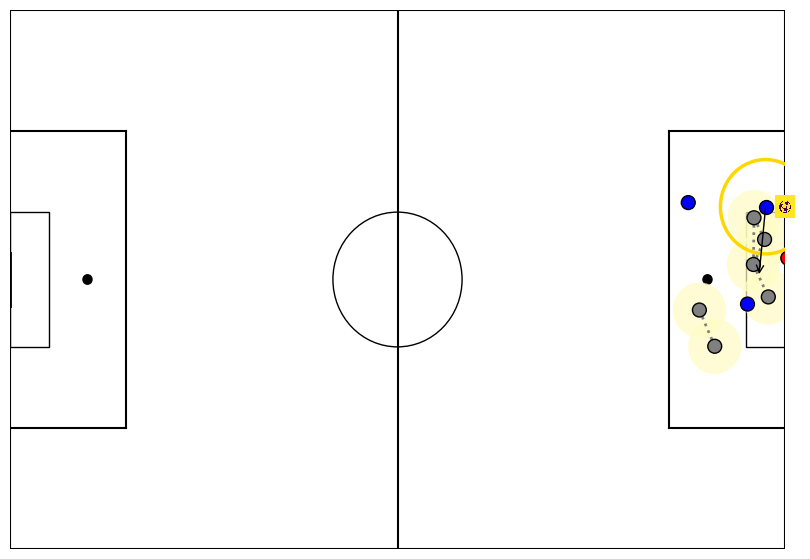

In [20]:
plot_three_sixty(frames_data,pass_x_start=pass_start_x, pass_y_start=pass_start_y, pass_x_end=pass_end_x, pass_y_end=pass_end_y, ball_icon_path="soccer_ball.png", ball_zoom=0.0055)

In [ ]:
#(DONE) to do (through balls):

    #(DONE) add the pass start and end to the plot 
    #(DONE) defender circle around the people closer to the goal than the passer 

    #(DONE) using the circles, draw connecting lines between defenders whose circles overlap (grey dotted line)

    #(DONE)answer the line-breaking boolean question - did that pass bisect any of the lines? 
        #currently the lines are within the plot. so we need to get them out and then use them and the pass coordinates to answer the question 

    #(DONE) get the other key moments 


#to do (general)
    #for each key moment, 
        #find the key pass to the person who did the event 
            #(WIP) shot - find the pass with them as the recipient 
                #(DONE) if key pass ID works
                #if key pass ID doesn't work 
            #penalty won - find the pass with them as the recipient
            #own goal - find the pass that gets intercepted or blocked by the person who scored the own goal

            
        #(DONE) find the event data in the previous 15 seconds to it 





    
#To do (one-twos)
    #use the first one as an example. make sure it works.


#to do (own goals)
    #if the Own GOal Against is preceded by a block or error, look at that x, y
    #then, find the pass or shot that directly precedes it within events_prior_10s

# Case 5: Layoff & Case 4: Cutback

In [7]:
# %% Helper: Check if pass travels away from goal
def pass_distance_away_from_goal(pass_location: Tuple[float, float], 
                                   pass_end_location: Tuple[float, float]) -> float:
    """
    Calculate how far a pass travels away from the goal.
    
    The goal is fixed at (120, 40) - the right side of the pitch.
    We calculate distance to this goal from both locations and see if the pass
    moves further away from the goal.
    
    Args:
        pass_location: Starting location (x, y)
        pass_end_location: Ending location (x, y)
    
    Returns:
        Distance traveled away from goal (positive if moving away, 0 if not)
    """
    x1, y1 = pass_location
    x2, y2 = pass_end_location
    
    # Distance to goal (120, 40) from start location
    dist_start_to_goal = math.hypot(x1 - 120.0, y1 - 40.0)
    
    # Distance to goal (120, 40) from end location
    dist_end_to_goal = math.hypot(x2 - 120.0, y2 - 40.0)
    
    # Distance traveled away from goal (positive if end is further than start)
    distance_away_from_goal = dist_end_to_goal - dist_start_to_goal
    
    # Return positive value only if moving away from goal, otherwise 0
    return max(0.0, distance_away_from_goal)

In [8]:
# %% Check Case 5: Layoff - pass_cross=0, travels away from goal, distance < 5m
def check_case5_layoff(events_df: pd.DataFrame, 
                        pass_id: Any, 
                        threshold_meters: float = 5.0) -> bool:
    """
    Check if a pass satisfies Case 5 (Layoff):
    - pass_cross column = 0 (False/0/NaN)
    - Pass travels away from goal
    - Pass travels less than threshold_meters
    
    Args:
        events_df: Full events DataFrame
        pass_id: ID of the pass event to check
        threshold_meters: Distance threshold (default 5.0 meters)
    
    Returns:
        True if all conditions are met, False otherwise
    """
    # Find the pass row
    pass_row = get_pass_row_by_id(events_df, pass_id)
    if pass_row is None:
        return False
    
    # Check pass_cross = 0 (False, 0, or NaN)
    pass_cross_val = pass_row.get("pass_cross", np.nan)
    is_not_cross = (
        pd.isna(pass_cross_val) or 
        pass_cross_val == False or 
        pass_cross_val == 0 or
        (isinstance(pass_cross_val, str) and pass_cross_val.lower() in ['false', '0', ''])
    )
    
    if not is_not_cross:
        return False  # pass_cross is not 0, so Case 5 fails
    
    # Get pass locations
    pass_loc = parse_xy(pass_row.get("location"))
    pass_end_loc = parse_xy(pass_row.get("pass_end_location"))
    
    if pass_loc is None or pass_end_loc is None:
        return False  # Missing location data
    
    # Check if pass travels away from goal
    dist_away = pass_distance_away_from_goal(pass_loc, pass_end_loc)
    if dist_away <= 0:
        return False  # Pass is not moving away from goal
    
    # Calculate actual pass distance (Pythagorean theorem)
    actual_pass_distance = math.hypot(
        pass_end_loc[0] - pass_loc[0],
        pass_end_loc[1] - pass_loc[1]
    )
    
    # Check if pass travels less than threshold
    return actual_pass_distance < threshold_meters

In [9]:
# %% Check Case 6: Cutback - pass_cross=0, travels away from goal, starts wider than goal mouth, distance > 5m
def check_case6_cutback(events_df: pd.DataFrame, 
                         pass_id: Any, 
                         threshold_meters: float = 5.0) -> bool:
    """
    Check if a pass satisfies Case 6 (Cutback):
    - pass_cross column = 0 (False/0/NaN)
    - Pass travels away from goal
    - Pass starts wider than goal mouth (Y > 44 OR Y < 36)
    - Pass travels more than threshold_meters
    
    Goal mouth width: Y between 36 and 44 (center at 40, ±4)
    Wider than goal mouth: Y > 44 OR Y < 36
    
    Args:
        events_df: Full events DataFrame
        pass_id: ID of the pass event to check
        threshold_meters: Distance threshold (default 5.0 meters)
    
    Returns:
        True if all conditions are met, False otherwise
    """
    # Find the pass row
    pass_row = get_pass_row_by_id(events_df, pass_id)
    if pass_row is None:
        return False
    
    # Check pass_cross = 0 (False, 0, or NaN)
    pass_cross_val = pass_row.get("pass_cross", np.nan)
    is_not_cross = (
        pd.isna(pass_cross_val) or 
        pass_cross_val == False or 
        pass_cross_val == 0 or
        (isinstance(pass_cross_val, str) and pass_cross_val.lower() in ['false', '0', ''])
    )
    
    if not is_not_cross:
        return False  # pass_cross is not 0, so Case 6 fails
    
    # Get pass locations
    pass_loc = parse_xy(pass_row.get("location"))
    pass_end_loc = parse_xy(pass_row.get("pass_end_location"))
    
    if pass_loc is None or pass_end_loc is None:
        return False  # Missing location data
    
    # Check if pass starts wider than goal mouth (Y > 44 OR Y < 36)
    y_start = pass_loc[1]
    is_wider_than_goal_mouth = (y_start > 44.0) or (y_start < 36.0)
    
    if not is_wider_than_goal_mouth:
        return False  # Pass doesn't start wider than goal mouth
    
    # Check if pass travels away from goal
    dist_away = pass_distance_away_from_goal(pass_loc, pass_end_loc)
    if dist_away <= 0:
        return False  # Pass is not moving away from goal
    
    # Calculate actual pass distance (Pythagorean theorem)
    actual_pass_distance = math.hypot(
        pass_end_loc[0] - pass_loc[0],
        pass_end_loc[1] - pass_loc[1]
    )
    
    # Check if pass travels more than threshold
    return actual_pass_distance > threshold_meters

In [ ]:
# # %% Classify shot moments with Case 1, Case 5, and Case 6 (multiple labels allowed)
# def classify_shot_moments(
#     filename: str,
#     moments_df: pd.DataFrame,
#     long_shot_yards: float = 22.0,
#     case1_threshold_meters: float = 5.0,
#     case5_threshold_meters: float = 5.0,
#     case6_threshold_meters: float = 5.0
# ) -> pd.DataFrame:
#     """
#     Classify important moments where type == 'Shot' with multi-labels and xG.
    
#     IMPORTANT: Cases 1, 5, and 6 can all apply simultaneously - multiple labels allowed
    
#     Labels (all can apply):
#       - Case 1: 'case1_pass_through_ball' if pass_cross=0 AND pass travels > threshold toward goal
#       - Case 5: 'case5_layoff' if pass_cross=0 AND pass travels away from goal AND distance < threshold
#       - Case 6: 'case6_cutback' if pass_cross=0 AND pass travels away from goal AND starts wider than goal mouth (Y>44 OR Y<36) AND distance > threshold
#       - pass_through_ball, pass_cross, pass_cut_back (from key pass flags)
#       - 'Long Shot' if distance to nearest goal center >= long_shot_yards
#       - 'other' if none of the above matched

#     Returns a DataFrame with one row per shot moment.
#     """
#     # Load full events for lookups (shot_key_pass_id, locations, xg, etc.)
#     ev = pd.read_csv(filename)

#     # Tolerant type column
#     type_col = "type" if "type" in ev.columns else ("Type" if "Type" in ev.columns else None)
#     if type_col is None:
#         raise ValueError("No 'type'/'Type' column in events CSV.")

#     # Shots in the full events
#     ev_shots = ev[ev[type_col].astype(str).str.lower() == "shot"].copy()

#     # Ensure an xg column exists on ev_shots
#     if "shot_statsbomb_xg" in ev_shots.columns:
#         ev_shots["xg"] = pd.to_numeric(ev_shots["shot_statsbomb_xg"], errors="coerce")
#     else:
#         ev_shots["xg"] = np.nan

#     # Focus only on the events that are marked as important moments AND are shots
#     if "type" not in moments_df.columns:
#         raise ValueError("moments_df must include a 'type' column.")
#     shot_ids = set(moments_df.loc[moments_df["type"] == "Shot", "id"]) if "id" in moments_df.columns else set()

#     if not shot_ids:
#         raise ValueError("moments_df must include 'id' for shot events to classify them.")

#     shots_focus = ev_shots[ev_shots["id"].isin(shot_ids)].copy()

#     # Prepare output rows
#     out_rows: List[Dict[str, Any]] = []

#     for _, r in shots_focus.iterrows():
#         labels: List[str] = []

#         # Check if shot has a key pass
#         kp = r.get("shot_key_pass_id", np.nan)
#         if pd.notna(kp):
#             # Check all cases independently - multiple can apply
#             # Case 1: pass_cross=0 AND travels toward goal > threshold
#             if check_case1_pass_toward_goal(ev, kp, threshold_meters=case1_threshold_meters):
#                 labels.append("case1_pass_through_ball")
            
#             # Case 5: pass_cross=0 AND travels away from goal AND distance < threshold
#             if check_case5_layoff(ev, kp, threshold_meters=case5_threshold_meters):
#                 labels.append("case5_layoff")
            
#             # Case 6: pass_cross=0 AND travels away from goal AND wider than goal mouth AND distance > threshold
#             if check_case6_cutback(ev, kp, threshold_meters=case6_threshold_meters):
#                 labels.append("case6_cutback")
            
#             # Also check original pass flags
#             prow = get_pass_row_by_id(ev, kp)
#             if prow is not None:
#                 if "pass_through_ball" in prow.index and pd.notna(prow["pass_through_ball"]) and bool(prow["pass_through_ball"]):
#                     labels.append("pass_through_ball")
#                 if "pass_cross" in prow.index and pd.notna(prow["pass_cross"]) and bool(prow["pass_cross"]):
#                     labels.append("pass_cross")
#                 if "pass_cut_back" in prow.index and pd.notna(prow["pass_cut_back"]) and bool(prow["pass_cut_back"]):
#                     labels.append("pass_cut_back")

#         # Long shot check
#         loc = parse_xy(r.get("location"))
#         dist_goal = float("nan")
#         if loc is not None:
#             dist_goal = dist_to_nearest_goal(loc)
#             if dist_goal >= float(long_shot_yards):
#                 labels.append("Long Shot")

#         # Other label (only if no other labels)
#         if len(labels) == 0:
#             labels.append("other")

#         # Calculate distance to goal for all shots (for reference)
#         if loc is None:
#             loc = parse_xy(r.get("location"))
#         if loc is not None and pd.isna(dist_goal):
#             dist_goal = dist_to_nearest_goal(loc)

#         out_rows.append({
#             "id": r.get("id"),
#             "match_id": r.get("match_id"),
#             "team": r.get("team"),
#             "player": r.get("player"),
#             "minute": r.get("minute"),
#             "second": r.get("second"),
#             "shot_outcome": r.get("shot_outcome"),
#             "xg": r.get("xg"),
#             "distance_to_goal": dist_goal,
#             "labels": labels,
#             "labels_str": ";".join(labels),
#             "shot_key_pass_id": r.get("shot_key_pass_id"),
#         })

#     shot_moments_labeled = pd.DataFrame(out_rows)

#     # Keep only the original important shot ids order if you want
#     order_ids = moments_df.loc[moments_df["type"] == "Shot", "id"].tolist()
#     if "id" in shot_moments_labeled.columns:
#         shot_moments_labeled["__order"] = shot_moments_labeled["id"].apply(lambda x: order_ids.index(x) if x in order_ids else 10**9)
#         shot_moments_labeled = shot_moments_labeled.sort_values("__order").drop(columns="__order")

#     return shot_moments_labeled

In [10]:
# %% Classify shot moments with Case 1, Case 5, and Case 6 ONLY (no other labels)
def classify_shot_moments(
    filename: str,
    moments_df: pd.DataFrame,
    long_shot_yards: float = 22.0,
    case1_threshold_meters: float = 5.0,
    case5_threshold_meters: float = 5.0,
    case6_threshold_meters: float = 5.0
) -> pd.DataFrame:
    """
    Classify important moments where type == 'Shot' with ONLY Cases 1, 5, and 6.
    
    Labels (only these cases):
      - Case 1: 'case1_pass_through_ball' if pass_cross=0 AND pass travels > threshold toward goal
      - Case 5: 'case5_layoff' if pass_cross=0 AND pass travels away from goal AND distance < threshold
      - Case 6: 'case6_cutback' if pass_cross=0 AND pass travels away from goal AND starts wider than goal mouth (Y>44 OR Y<36) AND distance > threshold
      - 'other' if none of the above matched

    Returns a DataFrame with one row per shot moment.
    """
    # Load full events for lookups (shot_key_pass_id, locations, xg, etc.)
    ev = pd.read_csv(filename)

    # Tolerant type column
    type_col = "type" if "type" in ev.columns else ("Type" if "Type" in ev.columns else None)
    if type_col is None:
        raise ValueError("No 'type'/'Type' column in events CSV.")

    # Shots in the full events
    ev_shots = ev[ev[type_col].astype(str).str.lower() == "shot"].copy()

    # Ensure an xg column exists on ev_shots
    if "shot_statsbomb_xg" in ev_shots.columns:
        ev_shots["xg"] = pd.to_numeric(ev_shots["shot_statsbomb_xg"], errors="coerce")
    else:
        ev_shots["xg"] = np.nan

    # Focus only on the events that are marked as important moments AND are shots
    if "type" not in moments_df.columns:
        raise ValueError("moments_df must include a 'type' column.")
    shot_ids = set(moments_df.loc[moments_df["type"] == "Shot", "id"]) if "id" in moments_df.columns else set()

    if not shot_ids:
        raise ValueError("moments_df must include 'id' for shot events to classify them.")

    shots_focus = ev_shots[ev_shots["id"].isin(shot_ids)].copy()

    # Prepare output rows
    out_rows: List[Dict[str, Any]] = []

    for _, r in shots_focus.iterrows():
        labels: List[str] = []

        # Check if shot has a key pass
        kp = r.get("shot_key_pass_id", np.nan)
        if pd.notna(kp):
            # Only check Cases 1, 5, and 6
            # Case 1: pass_cross=0 AND travels toward goal > threshold
            if check_case1_pass_toward_goal(ev, kp, threshold_meters=case1_threshold_meters):
                labels.append("case1_pass_through_ball")
            
            # Case 5: pass_cross=0 AND travels away from goal AND distance < threshold
            if check_case5_layoff(ev, kp, threshold_meters=case5_threshold_meters):
                labels.append("case5_layoff")
            
            # Case 6: pass_cross=0 AND travels away from goal AND wider than goal mouth AND distance > threshold
            if check_case6_cutback(ev, kp, threshold_meters=case6_threshold_meters):
                labels.append("case6_cutback")

        # Other label (only if no cases matched)
        if len(labels) == 0:
            labels.append("other")

        # Calculate distance to goal for all shots (for reference)
        loc = parse_xy(r.get("location"))
        dist_goal = float("nan")
        if loc is not None:
            dist_goal = dist_to_nearest_goal(loc)

        out_rows.append({
            "id": r.get("id"),
            "match_id": r.get("match_id"),
            "team": r.get("team"),
            "player": r.get("player"),
            "minute": r.get("minute"),
            "second": r.get("second"),
            "shot_outcome": r.get("shot_outcome"),
            "xg": r.get("xg"),
            "distance_to_goal": dist_goal,
            "labels": labels,
            "labels_str": ";".join(labels),
            "shot_key_pass_id": r.get("shot_key_pass_id"),
        })

    shot_moments_labeled = pd.DataFrame(out_rows)

    # Keep only the original important shot ids order if you want
    order_ids = moments_df.loc[moments_df["type"] == "Shot", "id"].tolist()
    if "id" in shot_moments_labeled.columns:
        shot_moments_labeled["__order"] = shot_moments_labeled["id"].apply(lambda x: order_ids.index(x) if x in order_ids else 10**9)
        shot_moments_labeled = shot_moments_labeled.sort_values("__order").drop(columns="__order")

    return shot_moments_labeled

In [138]:
# %% Main Execution with Cases 1, 5, and 6 (multiple labels allowed)
FILENAME = "events_by_match/events_3788741.csv" #3788754

# Step 1: Extract important moments
print("Extracting important moments...")
moments_df, moments_list = important_moments_from_file(FILENAME, xg_threshold=0.08)

print(f"\nFound {len(moments_df)} important moments")
print(f"  - Shots: {len(moments_df[moments_df['type'] == 'Shot'])}")
print(f"  - Own Goals: {len(moments_df[moments_df['type'] == 'Own Goal Against'])}")
print(f"  - Penalties Won: {len(moments_df[moments_df.get('shot_outcome', '') == 'Penalty Won'])}")

# Step 2: Classify shots with Cases 1, 5, and 6
print("\n\nClassifying shots...")
shot_moments_labeled = classify_shot_moments(
    FILENAME, 
    moments_df, 
    long_shot_yards=22.0,
    case1_threshold_meters=5.0,
    case5_threshold_meters=5.0,
    case6_threshold_meters=5.0
)

print(f"\nClassified {len(shot_moments_labeled)} shots")

# Summary of labels
print("\nLabel distribution (single labels):")
label_counts = shot_moments_labeled['labels_str'].value_counts()
print(label_counts)

# Show shots with Case 1 label (may have multiple labels)
case1_shots = shot_moments_labeled[shot_moments_labeled['labels_str'].str.contains('case1_pass_through_ball', na=False)]
print(f"\nShots with Case 1 label: {len(case1_shots)}")
if not case1_shots.empty:
    print("\nCase 1 shots (may have multiple labels):")
    with pd.option_context("display.max_columns", 50, "display.width", 180):
        print(case1_shots[['id', 'player', 'minute', 'second', 'xg', 'labels_str']].to_string(index=False))

# Show shots with Case 5 label (may have multiple labels)
case5_shots = shot_moments_labeled[shot_moments_labeled['labels_str'].str.contains('case5_layoff', na=False)]
print(f"\nShots with Case 5 label: {len(case5_shots)}")
if not case5_shots.empty:
    print("\nCase 5 (Layoff) shots (may have multiple labels):")
    with pd.option_context("display.max_columns", 50, "display.width", 180):
        print(case5_shots[['id', 'player', 'minute', 'second', 'xg', 'labels_str']].to_string(index=False))

# Show shots with Case 6 label (may have multiple labels)
case6_shots = shot_moments_labeled[shot_moments_labeled['labels_str'].str.contains('case6_cutback', na=False)]
print(f"\nShots with Case 6 label: {len(case6_shots)}")
if not case6_shots.empty:
    print("\nCase 6 (Cutback) shots (may have multiple labels):")
    with pd.option_context("display.max_columns", 50, "display.width", 180):
        print(case6_shots[['id', 'player', 'minute', 'second', 'xg', 'labels_str']].to_string(index=False))

# Show shots with multiple labels
multi_label_shots = shot_moments_labeled[shot_moments_labeled['labels_str'].str.count(';') > 0]
print(f"\nShots with multiple labels: {len(multi_label_shots)}")
if not multi_label_shots.empty:
    print("\nMultiple label shots:")
    with pd.option_context("display.max_columns", 50, "display.width", 180):
        print(multi_label_shots[['id', 'player', 'minute', 'second', 'xg', 'labels_str']].to_string(index=False))

# Display all results
print("\n\nAll labeled shots:")
with pd.option_context("display.max_columns", 50, "display.width", 180):
    print(shot_moments_labeled.to_string(index=False))

Extracting important moments...

Found 7 important moments
  - Shots: 6
  - Own Goals: 1
  - Penalties Won: 0


Classifying shots...

Classified 6 shots

Label distribution (single labels):
labels_str
case1_pass_through_ball    5
other                      1
Name: count, dtype: int64

Shots with Case 1 label: 5

Case 1 shots (may have multiple labels):
                                  id           player  minute  second       xg              labels_str
74750b41-c816-4a6c-88d3-b98859039c74  Lorenzo Insigne      17       3 0.098552 case1_pass_through_ball
c07133d1-fa88-45f8-8a40-7be381ddffd1 Domenico Berardi      44      33 0.128881 case1_pass_through_ball
c12c958c-b795-4471-b81c-c16582d8205a  Lorenzo Insigne      56      21 0.086273 case1_pass_through_ball
ead96180-5c0c-4ccb-b926-d215ba883fcb  Lorenzo Insigne      78      30 0.191777 case1_pass_through_ball
7d0764cb-f0d1-4424-9c97-e83a01388805     Burak Yılmaz      91      55 0.114827 case1_pass_through_ball

Shots with Case 5 label: 0

In [139]:
# %% Print pass details for Case 5 and Case 6 shots
FILENAME = "events_by_match/events_3788741.csv" #3788754

# Load events and important moments
ev = pd.read_csv(FILENAME)
moments_df, _ = important_moments_from_file(FILENAME, xg_threshold=0.08)

# Classify shots
shot_moments_labeled = classify_shot_moments(
    FILENAME,
    moments_df,
    long_shot_yards=22.0,
    case1_threshold_meters=5.0,
    case5_threshold_meters=5.0,
    case6_threshold_meters=5.0
)

# Filter shots with Case 5 or Case 6
case5_shots = shot_moments_labeled[shot_moments_labeled['labels_str'].str.contains('case5_layoff', na=False)]
case6_shots = shot_moments_labeled[shot_moments_labeled['labels_str'].str.contains('case6_cutback', na=False)]

print("="*100)
print("CASE 5 (LAYOFF) SHOTS")
print("="*100)

if case5_shots.empty:
    print("No shots with Case 5 label found.")
else:
    print(f"\nFound {len(case5_shots)} shot(s) with Case 5 label\n")
    
    for idx, shot_row in case5_shots.iterrows():
        shot_id = shot_row.get("id")
        kp_id = shot_row.get("shot_key_pass_id", np.nan)
        
        if pd.isna(kp_id):
            print(f"\nShot ID: {shot_id}")
            print(f"  No key pass ID")
            continue
        
        # Get the pass row
        pass_row = get_pass_row_by_id(ev, kp_id)
        if pass_row is None:
            print(f"\nShot ID: {shot_id}")
            print(f"  Key pass ID {kp_id} not found in events")
            continue
        
        print(f"\nShot ID: {shot_id}")
        print(f"  Player: {shot_row.get('player')}")
        print(f"  Minute: {shot_row.get('minute')}:{shot_row.get('second')}")
        print(f"  xG: {shot_row.get('xg')}")
        print(f"  Labels: {shot_row.get('labels_str')}")
        print(f"  Key Pass ID: {kp_id}")
        
        # Pass details
        print(f"\n  Pass details:")
        print(f"    pass_cross: {pass_row.get('pass_cross')}")
        print(f"    location: {pass_row.get('location')}")
        print(f"    pass_end_location: {pass_row.get('pass_end_location')}")
        
        # Parse locations
        pass_loc = parse_xy(pass_row.get("location"))
        pass_end_loc = parse_xy(pass_row.get("pass_end_location"))
        
        if pass_loc and pass_end_loc:
            print(f"\n    Parsed start location: {pass_loc}")
            print(f"    Parsed end location: {pass_end_loc}")
            
            # Calculate distances
            dist_start_to_goal = math.hypot(pass_loc[0] - 120.0, pass_loc[1] - 40.0)
            dist_end_to_goal = math.hypot(pass_end_loc[0] - 120.0, pass_end_loc[1] - 40.0)
            dist_toward = pass_distance_toward_goal(pass_loc, pass_end_loc)
            dist_away = pass_distance_away_from_goal(pass_loc, pass_end_loc)
            actual_dist = math.hypot(pass_end_loc[0] - pass_loc[0], pass_end_loc[1] - pass_loc[1])
            
            print(f"\n    Distance to goal at start: {dist_start_to_goal:.2f}")
            print(f"    Distance to goal at end: {dist_end_to_goal:.2f}")
            print(f"    Distance traveled toward goal: {dist_toward:.2f}")
            print(f"    Distance traveled away from goal: {dist_away:.2f}")
            print(f"    Actual pass distance: {actual_dist:.2f}")
            print(f"    Pass start Y coordinate: {pass_loc[1]:.2f}")
            
            # Verify Case 5 conditions
            print(f"\n    Case 5 conditions:")
            print(f"      - pass_cross = 0: {pass_row.get('pass_cross') == 0 or pd.isna(pass_row.get('pass_cross'))}")
            print(f"      - Pass travels away from goal: {dist_away > 0}")
            print(f"      - Pass distance < 5.0: {actual_dist < 5.0}")

print("\n" + "="*100)
print("CASE 6 (CUTBACK) SHOTS")
print("="*100)

if case6_shots.empty:
    print("No shots with Case 6 label found.")
else:
    print(f"\nFound {len(case6_shots)} shot(s) with Case 6 label\n")
    
    for idx, shot_row in case6_shots.iterrows():
        shot_id = shot_row.get("id")
        kp_id = shot_row.get("shot_key_pass_id", np.nan)
        
        if pd.isna(kp_id):
            print(f"\nShot ID: {shot_id}")
            print(f"  No key pass ID")
            continue
        
        # Get the pass row
        pass_row = get_pass_row_by_id(ev, kp_id)
        if pass_row is None:
            print(f"\nShot ID: {shot_id}")
            print(f"  Key pass ID {kp_id} not found in events")
            continue
        
        print(f"\nShot ID: {shot_id}")
        print(f"  Player: {shot_row.get('player')}")
        print(f"  Minute: {shot_row.get('minute')}:{shot_row.get('second')}")
        print(f"  xG: {shot_row.get('xg')}")
        print(f"  Labels: {shot_row.get('labels_str')}")
        print(f"  Key Pass ID: {kp_id}")
        
        # Pass details
        print(f"\n  Pass details:")
        print(f"    pass_cross: {pass_row.get('pass_cross')}")
        print(f"    location: {pass_row.get('location')}")
        print(f"    pass_end_location: {pass_row.get('pass_end_location')}")
        
        # Parse locations
        pass_loc = parse_xy(pass_row.get("location"))
        pass_end_loc = parse_xy(pass_row.get("pass_end_location"))
        
        if pass_loc and pass_end_loc:
            print(f"\n    Parsed start location: {pass_loc}")
            print(f"    Parsed end location: {pass_end_loc}")
            
            # Calculate distances
            dist_start_to_goal = math.hypot(pass_loc[0] - 120.0, pass_loc[1] - 40.0)
            dist_end_to_goal = math.hypot(pass_end_loc[0] - 120.0, pass_end_loc[1] - 40.0)
            dist_toward = pass_distance_toward_goal(pass_loc, pass_end_loc)
            dist_away = pass_distance_away_from_goal(pass_loc, pass_end_loc)
            actual_dist = math.hypot(pass_end_loc[0] - pass_loc[0], pass_end_loc[1] - pass_loc[1])
            
            print(f"\n    Distance to goal at start: {dist_start_to_goal:.2f}")
            print(f"    Distance to goal at end: {dist_end_to_goal:.2f}")
            print(f"    Distance traveled toward goal: {dist_toward:.2f}")
            print(f"    Distance traveled away from goal: {dist_away:.2f}")
            print(f"    Actual pass distance: {actual_dist:.2f}")
            print(f"    Pass start Y coordinate: {pass_loc[1]:.2f}")
            print(f"    Starts wider than goal mouth (Y>44 OR Y<36): {(pass_loc[1] > 44.0) or (pass_loc[1] < 36.0)}")
            
            # Verify Case 6 conditions
            print(f"\n    Case 6 conditions:")
            print(f"      - pass_cross = 0: {pass_row.get('pass_cross') == 0 or pd.isna(pass_row.get('pass_cross'))}")
            print(f"      - Pass travels away from goal: {dist_away > 0}")
            print(f"      - Starts wider than goal mouth (Y>44 OR Y<36): {(pass_loc[1] > 44.0) or (pass_loc[1] < 36.0)}")
            print(f"      - Pass distance > 5.0: {actual_dist > 5.0}")

print("\n" + "="*100)

CASE 5 (LAYOFF) SHOTS
No shots with Case 5 label found.

CASE 6 (CUTBACK) SHOTS
No shots with Case 6 label found.



In [141]:
# %% Find files with Case 5 or Case 6 labels
import os
import glob

# Path to events folder
EVENTS_FOLDER = "events_by_match"

# Get all CSV files in the folder
csv_files = glob.glob(os.path.join(EVENTS_FOLDER, "events_*.csv"))
csv_files.sort()

print(f"Found {len(csv_files)} event files to process")
print("="*80)

files_with_case5_or_case6 = []

for csv_file in csv_files:
    try:
        # Extract important moments
        moments_df, _ = important_moments_from_file(csv_file, xg_threshold=0.08)
        
        # Get shots from important moments
        shot_moments = moments_df[moments_df["type"] == "Shot"]
        
        if shot_moments.empty:
            continue
        
        # Classify shots
        shot_moments_labeled = classify_shot_moments(
            csv_file,
            moments_df,
            long_shot_yards=22.0,
            case1_threshold_meters=5.0,
            case5_threshold_meters=5.0,
            case6_threshold_meters=5.0
        )
        
        # Check for Case 5 or Case 6
        has_case5 = shot_moments_labeled['labels_str'].str.contains('case5_layoff', na=False).any()
        has_case6 = shot_moments_labeled['labels_str'].str.contains('case6_cutback', na=False).any()
        
        if has_case5 or has_case6:
            filename = os.path.basename(csv_file)
            case5_count = shot_moments_labeled['labels_str'].str.contains('case5_layoff', na=False).sum()
            case6_count = shot_moments_labeled['labels_str'].str.contains('case6_cutback', na=False).sum()
            
            files_with_case5_or_case6.append({
                'file': filename,
                'case5_count': case5_count,
                'case6_count': case6_count
            })
            
            print(f"✓ {filename}")
            if has_case5:
                print(f"  - Case 5 (Layoff): {case5_count} shot(s)")
            if has_case6:
                print(f"  - Case 6 (Cutback): {case6_count} shot(s)")
            
            # Stop after finding at least 2 files
            if len(files_with_case5_or_case6) >= 6:
                break
    
    except Exception as e:
        print(f"✗ Error processing {os.path.basename(csv_file)}: {str(e)}")
        continue

print("\n" + "="*80)
print(f"\nSummary: Found {len(files_with_case5_or_case6)} file(s) with Case 5 or Case 6:")
for item in files_with_case5_or_case6:
    print(f"  - {item['file']} (Case 5: {item['case5_count']}, Case 6: {item['case6_count']})")

Found 51 event files to process
✓ events_3788746.csv
  - Case 5 (Layoff): 1 shot(s)
✓ events_3788749.csv
  - Case 6 (Cutback): 1 shot(s)
✓ events_3788751.csv
  - Case 5 (Layoff): 1 shot(s)
✓ events_3788753.csv
  - Case 6 (Cutback): 1 shot(s)
✓ events_3788754.csv
  - Case 6 (Cutback): 2 shot(s)
✓ events_3788756.csv
  - Case 6 (Cutback): 1 shot(s)


Summary: Found 6 file(s) with Case 5 or Case 6:
  - events_3788746.csv (Case 5: 1, Case 6: 0)
  - events_3788749.csv (Case 5: 0, Case 6: 1)
  - events_3788751.csv (Case 5: 1, Case 6: 0)
  - events_3788753.csv (Case 5: 0, Case 6: 1)
  - events_3788754.csv (Case 5: 0, Case 6: 2)
  - events_3788756.csv (Case 5: 0, Case 6: 1)


# Case 2: early cross & Case 3: cross

In [11]:
# %% Helper: Get pitch zone from coordinates (1-18)
def get_pitch_zone(x: float, y: float) -> int:
    """
    Map (x, y) coordinates to pitch zone (1-18).
    
    Pitch dimensions: 120 x 80 units
    - X-axis: 6 vertical strips (0-20, 20-40, 40-60, 60-80, 80-100, 100-120)
    - Y-axis: 3 horizontal rows (0-26.67, 26.67-53.33, 53.33-80)
    
    Zone numbering:
    Top row:     1,  4,  7, 10, 13, 16
    Middle row:  2,  5,  8, 11, 14, 17
    Bottom row:  3,  6,  9, 12, 15, 18
    
    Args:
        x: X coordinate (0-120)
        y: Y coordinate (0-80)
    
    Returns:
        Zone number (1-18)
    """
    # Vertical strips (X-axis)
    if x < 20:
        col = 0
    elif x < 40:
        col = 1
    elif x < 60:
        col = 2
    elif x < 80:
        col = 3
    elif x < 100:
        col = 4
    else:  # x >= 100 and x <= 120
        col = 5
    
    # Horizontal rows (Y-axis)
    if y < (80/3):  # y < 26.67
        row = 2  # Bottom row
    elif y < (80*2/3):  # y < 53.33
        row = 1  # Middle row
    else:  # y >= 53.33
        row = 0  # Top row
    
    # Zone number formula: row * 6 + col + 1
    zone = row * 6 + col + 1
    return zone

In [12]:
# %% Helper: Load 360 data for a specific event
def load_360_data_for_event(match_id: int, event_id: str, frames_360_folder_path: str) -> pd.DataFrame:
    """
    Load 360 data for a specific event from the frames_360 CSV file.
    
    Args:
        match_id: Match ID (e.g., 3788741)
        event_id: Event ID (pass ID) to filter by
        frames_360_folder_path: Path to frames_360_by_match folder
    
    Returns:
        DataFrame with rows matching the event_id, or empty DataFrame if not found
    """
    # Construct path to 360 data file
    frames_360_file = f"{frames_360_folder_path}/frames_360_{match_id}.csv"
    
    try:
        # Load the CSV file
        df_360 = pd.read_csv(frames_360_file)
        
        # Filter rows where id matches event_id
        filtered = df_360[df_360["id"] == event_id].copy()
        
        return filtered
    except FileNotFoundError:
        print(f"Warning: 360 data file not found: {frames_360_file}")
        return pd.DataFrame()
    except Exception as e:
        print(f"Warning: Error loading 360 data: {e}")
        return pd.DataFrame()

In [13]:
# %% Helper: Count teammates in penalty box using 360 data
def count_teammates_in_box(match_id: int, event_id: str, frames_360_folder_path: str) -> int:
    """
    Count number of teammates in the penalty box at the time of the event.
    
    Penalty box coordinates (approximate):
    - X: [102, 120] (from ~18 yards back to goal line)
    - Y: [18, 62] (centered on Y=40, ±22 units)
    
    Args:
        match_id: Match ID
        event_id: Event ID (pass ID) to get 360 data for
        frames_360_folder_path: Path to frames_360_by_match folder
    
    Returns:
        Number of teammates in the penalty box
    """
    # Load 360 data for this event
    df_360 = load_360_data_for_event(match_id, event_id, frames_360_folder_path)
    
    if df_360.empty:
        return 0
    
    # Penalty box boundaries
    x_min_box = 102
    x_max_box = 120
    y_min_box = 18
    y_max_box = 62
    
    teammate_count = 0
    
    # Iterate through each row (each player/object at the event)
    for _, row in df_360.iterrows():
        # Check if teammate
        is_teammate = row.get("teammate", 0)
        if is_teammate != 1:
            continue
        
        # Parse location
        location_str = row.get("location", None)
        if pd.isna(location_str):
            continue
        
        loc = parse_xy(location_str)
        if loc is None:
            continue
        
        x, y = loc
        
        # Check if location is within penalty box
        if (x_min_box <= x <= x_max_box) and (y_min_box <= y <= y_max_box):
            teammate_count += 1
    
    return teammate_count

In [14]:
# %% Check Case 2: Early Cross - pass_cross=1, zone 10-15, 0 teammates in box
def check_case2_early_cross(
    events_df: pd.DataFrame,
    pass_id: str,
    match_id: int,
    frames_360_folder_path: str
) -> bool:
    """
    Check if a pass satisfies Case 2 (Early Cross):
    - pass_cross column = 1 (True/1)
    - Pass location in zones 10-15
    - 0 teammates in penalty box (using 360 data)
    
    Args:
        events_df: Full events DataFrame
        pass_id: ID of the pass event to check
        match_id: Match ID for 360 data lookup
        frames_360_folder_path: Path to frames_360_by_match folder
    
    Returns:
        True if all conditions are met, False otherwise
    """
    # Find the pass row
    pass_row = get_pass_row_by_id(events_df, pass_id)
    if pass_row is None:
        return False
    
    # Check pass_cross = 1 (True, 1, or truthy)
    pass_cross_val = pass_row.get("pass_cross", np.nan)
    is_cross = (
        pd.notna(pass_cross_val) and 
        (pass_cross_val == 1 or pass_cross_val == True or 
         (isinstance(pass_cross_val, (int, float)) and pass_cross_val == 1.0))
    )
    
    if not is_cross:
        return False  # pass_cross is not 1, so Case 2 fails
    
    # Get pass location
    pass_loc = parse_xy(pass_row.get("location"))
    if pass_loc is None:
        return False  # Missing location data
    
    # Check if pass is in zones 10-15
    zone = get_pitch_zone(pass_loc[0], pass_loc[1])
    if zone not in [10, 11, 12, 13, 14, 15]:
        return False  # Pass not in zones 10-15
    
    # Count teammates in box
    num_teammates = count_teammates_in_box(match_id, pass_id, frames_360_folder_path)
    
    # Check if 0 teammates in box
    return num_teammates == 0

In [15]:
# %% Check Case 3: Cross - pass_cross=1, (zone 10-15 with >=1 teammates) OR (zone 16-18)
def check_case3_cross(
    events_df: pd.DataFrame,
    pass_id: str,
    match_id: int,
    frames_360_folder_path: str
) -> bool:
    """
    Check if a pass satisfies Case 3 (Cross):
    - pass_cross column = 1 (True/1)
    - Either:
      a) Pass location in zones 10-15 AND >=1 teammates in penalty box (using 360 data)
      b) Pass location in zones 16-18 (no teammate check needed)
    
    Args:
        events_df: Full events DataFrame
        pass_id: ID of the pass event to check
        match_id: Match ID for 360 data lookup
        frames_360_folder_path: Path to frames_360_by_match folder
    
    Returns:
        True if all conditions are met, False otherwise
    """
    # Find the pass row
    pass_row = get_pass_row_by_id(events_df, pass_id)
    if pass_row is None:
        return False
    
    # Check pass_cross = 1 (True, 1, or truthy)
    pass_cross_val = pass_row.get("pass_cross", np.nan)
    is_cross = (
        pd.notna(pass_cross_val) and 
        (pass_cross_val == 1 or pass_cross_val == True or 
         (isinstance(pass_cross_val, (int, float)) and pass_cross_val == 1.0))
    )
    
    if not is_cross:
        return False  # pass_cross is not 1, so Case 3 fails
    
    # Get pass location
    pass_loc = parse_xy(pass_row.get("location"))
    if pass_loc is None:
        return False  # Missing location data
    
    # Check zone
    zone = get_pitch_zone(pass_loc[0], pass_loc[1])
    
    # Case 3a: Zones 10-15 with >=1 teammates in box
    if zone in [10, 11, 12, 13, 14, 15]:
        num_teammates = count_teammates_in_box(match_id, pass_id, frames_360_folder_path)
        return num_teammates >= 1
    
    # Case 3b: Zones 16-18 (no teammate check needed)
    if zone in [16, 17, 18]:
        return True
    
    # Not in relevant zones
    return False

In [16]:
# %% Updated classify_shot_moments with Cases 1, 2, 3, 5, and 6 (multiple labels allowed)
def classify_shot_moments(
    filename: str,
    moments_df: pd.DataFrame,
    long_shot_yards: float = 22.0,
    case1_threshold_meters: float = 5.0,
    case5_threshold_meters: float = 5.0,
    case6_threshold_meters: float = 5.0,
    frames_360_folder_path: str = "../frames_360_by_match"
) -> pd.DataFrame:
    """
    Classify important moments where type == 'Shot' with Cases 1, 2, 3, 5, and 6.
    
    IMPORTANT: Multiple labels allowed - all applicable cases can be assigned
    
    Labels (all can apply):
      - Case 1: 'case1_pass_through_ball' if pass_cross=0 AND pass travels > threshold toward goal
      - Case 2: 'case2_early_cross' if pass_cross=1 AND zone 10-15 AND 0 teammates in box
      - Case 3: 'case3_cross' if pass_cross=1 AND ((zone 10-15 AND >=1 teammates) OR zone 16-18)
      - Case 5: 'case5_layoff' if pass_cross=0 AND pass travels away from goal AND distance < threshold
      - Case 6: 'case6_cutback' if pass_cross=0 AND pass travels away from goal AND starts wider than goal mouth AND distance > threshold
      - 'other' if none of the above matched

    Returns a DataFrame with one row per shot moment.
    """
    # Load full events for lookups (shot_key_pass_id, locations, xg, etc.)
    ev = pd.read_csv(filename)

    # Tolerant type column
    type_col = "type" if "type" in ev.columns else ("Type" if "Type" in ev.columns else None)
    if type_col is None:
        raise ValueError("No 'type'/'Type' column in events CSV.")

    # Shots in the full events
    ev_shots = ev[ev[type_col].astype(str).str.lower() == "shot"].copy()

    # Ensure an xg column exists on ev_shots
    if "shot_statsbomb_xg" in ev_shots.columns:
        ev_shots["xg"] = pd.to_numeric(ev_shots["shot_statsbomb_xg"], errors="coerce")
    else:
        ev_shots["xg"] = np.nan

    # Focus only on the events that are marked as important moments AND are shots
    if "type" not in moments_df.columns:
        raise ValueError("moments_df must include a 'type' column.")
    shot_ids = set(moments_df.loc[moments_df["type"] == "Shot", "id"]) if "id" in moments_df.columns else set()

    if not shot_ids:
        raise ValueError("moments_df must include 'id' for shot events to classify them.")

    shots_focus = ev_shots[ev_shots["id"].isin(shot_ids)].copy()

    # Prepare output rows
    out_rows: List[Dict[str, Any]] = []

    for _, r in shots_focus.iterrows():
        labels: List[str] = []
        
        # Get match_id for 360 data lookup
        match_id = r.get("match_id", None)
        if pd.isna(match_id):
            match_id = None

        # Check if shot has a key pass
        kp = r.get("shot_key_pass_id", np.nan)
        if pd.notna(kp) and match_id is not None:
            # Check all cases independently - multiple can apply
            # Case 1: pass_cross=0 AND travels toward goal > threshold
            if check_case1_pass_toward_goal(ev, kp, threshold_meters=case1_threshold_meters):
                labels.append("case1_pass_through_ball")
            
            # Case 2: pass_cross=1 AND zone 10-15 AND 0 teammates in box
            if check_case2_early_cross(ev, kp, match_id, frames_360_folder_path):
                labels.append("case2_early_cross")
            
            # Case 3: pass_cross=1 AND ((zone 10-15 AND >=1 teammates) OR zone 16-18)
            if check_case3_cross(ev, kp, match_id, frames_360_folder_path):
                labels.append("case3_cross")
            
            # Case 5: pass_cross=0 AND travels away from goal AND distance < threshold
            if check_case5_layoff(ev, kp, threshold_meters=case5_threshold_meters):
                labels.append("case5_layoff")
            
            # Case 6: pass_cross=0 AND travels away from goal AND wider than goal mouth AND distance > threshold
            if check_case6_cutback(ev, kp, threshold_meters=case6_threshold_meters):
                labels.append("case6_cutback")

        # Other label (only if no cases matched)
        if len(labels) == 0:
            labels.append("other")

        # Calculate distance to goal for all shots (for reference)
        loc = parse_xy(r.get("location"))
        dist_goal = float("nan")
        if loc is not None:
            dist_goal = dist_to_nearest_goal(loc)

        out_rows.append({
            "id": r.get("id"),
            "match_id": r.get("match_id"),
            "team": r.get("team"),
            "player": r.get("player"),
            "minute": r.get("minute"),
            "second": r.get("second"),
            "shot_outcome": r.get("shot_outcome"),
            "xg": r.get("xg"),
            "distance_to_goal": dist_goal,
            "labels": labels,
            "labels_str": ";".join(labels),
            "shot_key_pass_id": r.get("shot_key_pass_id"),
        })

    shot_moments_labeled = pd.DataFrame(out_rows)

    # Keep only the original important shot ids order if you want
    order_ids = moments_df.loc[moments_df["type"] == "Shot", "id"].tolist()
    if "id" in shot_moments_labeled.columns:
        shot_moments_labeled["__order"] = shot_moments_labeled["id"].apply(lambda x: order_ids.index(x) if x in order_ids else 10**9)
        shot_moments_labeled = shot_moments_labeled.sort_values("__order").drop(columns="__order")

    return shot_moments_labeled

In [24]:
# %% Scan event files for Case 2 (5 events) and Case 3 (5 events)
import os
import glob

EVENTS_FOLDER = "events_by_match"
FRAMES_360_PATH = "frames_360_by_match"

# Get all CSV files in the folder
csv_files = glob.glob(os.path.join(EVENTS_FOLDER, "events_*.csv"))
csv_files.sort()

print(f"Scanning {len(csv_files)} event files for Case 2 and Case 3...")
print("="*100)

events_with_case2 = []
events_with_case3 = []

for csv_file in csv_files:
    try:
        # Extract important moments
        moments_df, _ = important_moments_from_file(csv_file, xg_threshold=0.08)
        
        # Get shots from important moments
        shot_moments = moments_df[moments_df["type"] == "Shot"]
        
        if shot_moments.empty:
            continue
        
        # Classify shots
        shot_moments_labeled = classify_shot_moments(
            csv_file,
            moments_df,
            long_shot_yards=22.0,
            case1_threshold_meters=5.0,
            case5_threshold_meters=5.0,
            case6_threshold_meters=5.0,
            frames_360_folder_path=FRAMES_360_PATH
        )
        
        # Check for Case 2
        if len(events_with_case2) < 5:
            case2_mask = shot_moments_labeled['labels_str'].str.contains('case2_early_cross', na=False)
            case2_shots = shot_moments_labeled[case2_mask]
            
            for _, shot_row in case2_shots.iterrows():
                if len(events_with_case2) >= 5:
                    break
                
                match_id = shot_row.get("match_id")
                shot_id = shot_row.get("id")
                kp_id = shot_row.get("shot_key_pass_id")
                labels = shot_row.get("labels_str", "")
                
                # Only add if it has Case 2 (may have other labels too)
                if "case2_early_cross" in labels:
                    events_with_case2.append({
                        'file': os.path.basename(csv_file),
                        'match_id': match_id,
                        'shot_id': shot_id,
                        'key_pass_id': kp_id,
                        'player': shot_row.get('player'),
                        'minute': shot_row.get('minute'),
                        'second': shot_row.get('second'),
                        'xg': shot_row.get('xg'),
                        'labels': labels
                    })
        
        # Check for Case 3
        if len(events_with_case3) < 5:
            case3_mask = shot_moments_labeled['labels_str'].str.contains('case3_cross', na=False)
            case3_shots = shot_moments_labeled[case3_mask]
            
            for _, shot_row in case3_shots.iterrows():
                if len(events_with_case3) >= 5:
                    break
                
                match_id = shot_row.get("match_id")
                shot_id = shot_row.get("id")
                kp_id = shot_row.get("shot_key_pass_id")
                labels = shot_row.get("labels_str", "")
                
                # Only add if it has Case 3 (may have other labels too)
                if "case3_cross" in labels:
                    events_with_case3.append({
                        'file': os.path.basename(csv_file),
                        'match_id': match_id,
                        'shot_id': shot_id,
                        'key_pass_id': kp_id,
                        'player': shot_row.get('player'),
                        'minute': shot_row.get('minute'),
                        'second': shot_row.get('second'),
                        'xg': shot_row.get('xg'),
                        'labels': labels
                    })
        
        # Stop if we have both
        if len(events_with_case2) >= 5 and len(events_with_case3) >= 5:
            break
    
    except Exception as e:
        print(f"✗ Error processing {os.path.basename(csv_file)}: {str(e)}")
        continue

print("\n" + "="*100)
print("CASE 2 (EARLY CROSS) EVENTS")
print("="*100)
print(f"\nFound {len(events_with_case2)} event(s) with Case 2")

for i, event in enumerate(events_with_case2, 1):
    print(f"\n{i}. File: {event['file']}")
    print(f"   Match ID: {event['match_id']}")
    print(f"   Shot ID: {event['shot_id']}")
    print(f"   Player: {event['player']}")
    print(f"   Time: {event['minute']}:{event['second']}")
    print(f"   xG: {event['xg']}")
    print(f"   Key Pass ID: {event['key_pass_id']}")
    print(f"   Labels: {event['labels']}")

print("\n" + "="*100)
print("CASE 3 (CROSS) EVENTS")
print("="*100)
print(f"\nFound {len(events_with_case3)} event(s) with Case 3")

for i, event in enumerate(events_with_case3, 1):
    print(f"\n{i}. File: {event['file']}")
    print(f"   Match ID: {event['match_id']}")
    print(f"   Shot ID: {event['shot_id']}")
    print(f"   Player: {event['player']}")
    print(f"   Time: {event['minute']}:{event['second']}")
    print(f"   xG: {event['xg']}")
    print(f"   Key Pass ID: {event['key_pass_id']}")
    print(f"   Labels: {event['labels']}")

print("\n" + "="*100)
print(f"\nSummary:")
print(f"  Case 2 events found: {len(events_with_case2)}/5")
print(f"  Case 3 events found: {len(events_with_case3)}/5")

Scanning 51 event files for Case 2 and Case 3...

CASE 2 (EARLY CROSS) EVENTS

Found 0 event(s) with Case 2

CASE 3 (CROSS) EVENTS

Found 5 event(s) with Case 3

1. File: events_3788742.csv
   Match ID: 3788742
   Shot ID: 4e0a9f53-2178-4a45-bd78-4ae93c7cbbe9
   Player: Jonas Older Wind
   Time: 11:22
   xG: 0.13215932
   Key Pass ID: fc8f2e18-47eb-42b0-8644-5f326c89bfb9
   Labels: case3_cross

2. File: events_3788742.csv
   Match ID: 3788742
   Shot ID: da5fbab8-0347-4369-9056-df040c778889
   Player: Joel Pohjanpalo
   Time: 59:2
   xG: 0.2884817
   Key Pass ID: c6a8b8c1-e63a-47df-bff0-608cfbc649d4
   Labels: case3_cross

3. File: events_3788742.csv
   Match ID: 3788742
   Shot ID: 92110c7a-9818-4829-936d-913c2e5b9aad
   Player: Jannik Vestergaard
   Time: 92:12
   xG: 0.12056617
   Key Pass ID: 5aa91c26-1129-45b1-8dbf-1eab973bc3f5
   Labels: case3_cross

4. File: events_3788745.csv
   Match ID: 3788745
   Shot ID: f09c2400-8459-43ca-9b87-f5cef3dc0e97
   Player: Harry Kane
   Time: 60

In [25]:
# %% Main Execution with Cases 1, 2, 3, 5, and 6
FILENAME = "events_by_match/events_3788742.csv"
FRAMES_360_PATH = "frames_360_by_match"

# Step 1: Extract important moments
print("Extracting important moments...")
moments_df, moments_list = important_moments_from_file(FILENAME, xg_threshold=0.08)

print(f"\nFound {len(moments_df)} important moments")
print(f"  - Shots: {len(moments_df[moments_df['type'] == 'Shot'])}")

# Step 2: Classify shots with all cases
print("\n\nClassifying shots...")
shot_moments_labeled = classify_shot_moments(
    FILENAME, 
    moments_df, 
    long_shot_yards=22.0,
    case1_threshold_meters=5.0,
    case5_threshold_meters=5.0,
    case6_threshold_meters=5.0,
    frames_360_folder_path=FRAMES_360_PATH
)

print(f"\nClassified {len(shot_moments_labeled)} shots")

# Summary of labels
print("\nLabel distribution:")
label_counts = shot_moments_labeled['labels_str'].value_counts()
print(label_counts)

# Show shots with different cases
case1_shots = shot_moments_labeled[shot_moments_labeled['labels_str'].str.contains('case1_pass_through_ball', na=False)]
case2_shots = shot_moments_labeled[shot_moments_labeled['labels_str'].str.contains('case2_early_cross', na=False)]
case3_shots = shot_moments_labeled[shot_moments_labeled['labels_str'].str.contains('case3_cross', na=False)]
case5_shots = shot_moments_labeled[shot_moments_labeled['labels_str'].str.contains('case5_layoff', na=False)]
case6_shots = shot_moments_labeled[shot_moments_labeled['labels_str'].str.contains('case6_cutback', na=False)]

print(f"\nShots by case:")
print(f"  Case 1: {len(case1_shots)}")
print(f"  Case 2: {len(case2_shots)}")
print(f"  Case 3: {len(case3_shots)}")
print(f"  Case 5: {len(case5_shots)}")
print(f"  Case 6: {len(case6_shots)}")

# Show shots with multiple labels
multi_label_shots = shot_moments_labeled[shot_moments_labeled['labels_str'].str.count(';') > 0]
print(f"\nShots with multiple labels: {len(multi_label_shots)}")
if not multi_label_shots.empty:
    print("\nMultiple label shots:")
    with pd.option_context("display.max_columns", 50, "display.width", 180):
        print(multi_label_shots[['id', 'player', 'minute', 'second', 'xg', 'labels_str']].to_string(index=False))

# Display all results
print("\n\nAll labeled shots:")
with pd.option_context("display.max_columns", 50, "display.width", 180):
    print(shot_moments_labeled.to_string(index=False))

Extracting important moments...

Found 7 important moments
  - Shots: 6


Classifying shots...

Classified 6 shots

Label distribution:
labels_str
case3_cross                3
case1_pass_through_ball    2
other                      1
Name: count, dtype: int64

Shots by case:
  Case 1: 2
  Case 2: 0
  Case 3: 3
  Case 5: 0
  Case 6: 0

Shots with multiple labels: 0


All labeled shots:
                                  id  match_id    team                  player  minute  second shot_outcome       xg  distance_to_goal                    labels              labels_str                     shot_key_pass_id
4e0a9f53-2178-4a45-bd78-4ae93c7cbbe9   3788742 Denmark        Jonas Older Wind      11      22        Off T 0.132159          7.280110             [case3_cross]             case3_cross fc8f2e18-47eb-42b0-8644-5f326c89bfb9
78cb3024-7db8-439b-9682-ae9ed18baa7b   3788742 Denmark   Pierre-Emile Højbjerg      14      44        Saved 0.086957         10.700467 [case1_pass_through_ball] case1_p

In [27]:
# %% Print pass details for Case 2 and Case 3 shots
FILENAME = "events_by_match/events_3788742.csv"
FRAMES_360_PATH = "frames_360_by_match"

# Load events and important moments
ev = pd.read_csv(FILENAME)
moments_df, _ = important_moments_from_file(FILENAME, xg_threshold=0.08)

# Classify shots
shot_moments_labeled = classify_shot_moments(
    FILENAME,
    moments_df,
    long_shot_yards=22.0,
    case1_threshold_meters=5.0,
    case5_threshold_meters=5.0,
    case6_threshold_meters=5.0,
    frames_360_folder_path=FRAMES_360_PATH
)

# Filter shots with Case 2 or Case 3
case2_shots = shot_moments_labeled[shot_moments_labeled['labels_str'].str.contains('case2_early_cross', na=False)]
case3_shots = shot_moments_labeled[shot_moments_labeled['labels_str'].str.contains('case3_cross', na=False)]

print("="*100)
print("CASE 2 (EARLY CROSS) SHOTS")
print("="*100)

if case2_shots.empty:
    print("No shots with Case 2 label found.")
else:
    print(f"\nFound {len(case2_shots)} shot(s) with Case 2 label\n")
    
    for idx, shot_row in case2_shots.iterrows():
        shot_id = shot_row.get("id")
        kp_id = shot_row.get("shot_key_pass_id", np.nan)
        match_id = shot_row.get("match_id")
        
        if pd.isna(kp_id):
            print(f"\nShot ID: {shot_id}")
            print(f"  No key pass ID")
            continue
        
        # Get the pass row
        pass_row = get_pass_row_by_id(ev, kp_id)
        if pass_row is None:
            print(f"\nShot ID: {shot_id}")
            print(f"  Key pass ID {kp_id} not found in events")
            continue
        
        print(f"\nShot ID: {shot_id}")
        print(f"  Player: {shot_row.get('player')}")
        print(f"  Minute: {shot_row.get('minute')}:{shot_row.get('second')}")
        print(f"  xG: {shot_row.get('xg')}")
        print(f"  Labels: {shot_row.get('labels_str')}")
        print(f"  Key Pass ID: {kp_id}")
        print(f"  Match ID: {match_id}")
        
        # Pass details
        print(f"\n  Pass details:")
        print(f"    pass_cross: {pass_row.get('pass_cross')}")
        print(f"    location: {pass_row.get('location')}")
        print(f"    pass_end_location: {pass_row.get('pass_end_location')}")
        
        # Parse locations
        pass_loc = parse_xy(pass_row.get("location"))
        pass_end_loc = parse_xy(pass_row.get("pass_end_location"))
        
        if pass_loc:
            zone = get_pitch_zone(pass_loc[0], pass_loc[1])
            print(f"\n    Parsed start location: {pass_loc}")
            print(f"    Zone: {zone}")
            print(f"    In zones 10-15? {zone in [10, 11, 12, 13, 14, 15]}")
            
            # Count teammates in box
            num_teammates = count_teammates_in_box(match_id, kp_id, FRAMES_360_PATH)
            print(f"    Teammates in penalty box: {num_teammates}")
            
            # Verify Case 2 conditions
            print(f"\n    Case 2 conditions:")
            print(f"      - pass_cross = 1: {pass_row.get('pass_cross') == 1}")
            print(f"      - Pass in zones 10-15: {zone in [10, 11, 12, 13, 14, 15]}")
            print(f"      - 0 teammates in box: {num_teammates == 0}")

print("\n" + "="*100)
print("CASE 3 (CROSS) SHOTS")
print("="*100)

if case3_shots.empty:
    print("No shots with Case 3 label found.")
else:
    print(f"\nFound {len(case3_shots)} shot(s) with Case 3 label\n")
    
    for idx, shot_row in case3_shots.iterrows():
        shot_id = shot_row.get("id")
        kp_id = shot_row.get("shot_key_pass_id", np.nan)
        match_id = shot_row.get("match_id")
        
        if pd.isna(kp_id):
            print(f"\nShot ID: {shot_id}")
            print(f"  No key pass ID")
            continue
        
        # Get the pass row
        pass_row = get_pass_row_by_id(ev, kp_id)
        if pass_row is None:
            print(f"\nShot ID: {shot_id}")
            print(f"  Key pass ID {kp_id} not found in events")
            continue
        
        print(f"\nShot ID: {shot_id}")
        print(f"  Player: {shot_row.get('player')}")
        print(f"  Minute: {shot_row.get('minute')}:{shot_row.get('second')}")
        print(f"  xG: {shot_row.get('xg')}")
        print(f"  Labels: {shot_row.get('labels_str')}")
        print(f"  Key Pass ID: {kp_id}")
        print(f"  Match ID: {match_id}")
        
        # Pass details
        print(f"\n  Pass details:")
        print(f"    pass_cross: {pass_row.get('pass_cross')}")
        print(f"    location: {pass_row.get('location')}")
        print(f"    pass_end_location: {pass_row.get('pass_end_location')}")
        
        # Parse locations
        pass_loc = parse_xy(pass_row.get("location"))
        pass_end_loc = parse_xy(pass_row.get("pass_end_location"))
        
        if pass_loc:
            zone = get_pitch_zone(pass_loc[0], pass_loc[1])
            print(f"\n    Parsed start location: {pass_loc}")
            print(f"    Zone: {zone}")
            print(f"    In zones 10-15? {zone in [10, 11, 12, 13, 14, 15]}")
            print(f"    In zones 16-18? {zone in [16, 17, 18]}")
            
            # Count teammates in box
            num_teammates = count_teammates_in_box(match_id, kp_id, FRAMES_360_PATH)
            print(f"    Teammates in penalty box: {num_teammates}")
            
            # Verify Case 3 conditions
            print(f"\n    Case 3 conditions:")
            print(f"      - pass_cross = 1: {pass_row.get('pass_cross') == 1}")
            if zone in [10, 11, 12, 13, 14, 15]:
                print(f"      - Pass in zones 10-15: True")
                print(f"      - >=1 teammates in box: {num_teammates >= 1}")
            elif zone in [16, 17, 18]:
                print(f"      - Pass in zones 16-18: True")
                print(f"      - No teammate check needed for zones 16-18")

print("\n" + "="*100)

CASE 2 (EARLY CROSS) SHOTS
No shots with Case 2 label found.

CASE 3 (CROSS) SHOTS

Found 3 shot(s) with Case 3 label


Shot ID: 4e0a9f53-2178-4a45-bd78-4ae93c7cbbe9
  Player: Jonas Older Wind
  Minute: 11:22
  xG: 0.13215932
  Labels: case3_cross
  Key Pass ID: fc8f2e18-47eb-42b0-8644-5f326c89bfb9
  Match ID: 3788742

  Pass details:
    pass_cross: 1.0
    location: [105.1, 15.4]
    pass_end_location: [111.9, 39.3]

    Parsed start location: (105.1, 15.4)
    Zone: 18
    In zones 10-15? False
    In zones 16-18? True
    Teammates in penalty box: 3

    Case 3 conditions:
      - pass_cross = 1: True
      - Pass in zones 16-18: True
      - No teammate check needed for zones 16-18

Shot ID: da5fbab8-0347-4369-9056-df040c778889
  Player: Joel Pohjanpalo
  Minute: 59:2
  xG: 0.2884817
  Labels: case3_cross
  Key Pass ID: c6a8b8c1-e63a-47df-bff0-608cfbc649d4
  Match ID: 3788742

  Pass details:
    pass_cross: 1.0
    location: [100.6, 11.0]
    pass_end_location: [111.5, 42.4]

   